# Case study: the summer 2012 central U.S. heat wave

An ensemble, multi-start sensitivity case study of the late-June to early-July 2012 central U.S. heat episode, evaluated with event-centred and S2S lead-centred diagnostics under the prescribed observed SST of the F20TR hindcasts. It is one event seen from four overlapping May starts: the results are case-specific sensitivities to initialization, not climatological forecast skill. Process diagnostics (antecedent precipitation and soil moisture, surface energy partitioning, cloud and radiation, ridge evolution) follow in a later notebook once these results show what differs.

## Two evaluation frameworks

| Framework | Time coordinate | Question |
|---|---|---|
| Event-centred | calendar date | How well does each experiment represent the observed event window, seen from every start? |
| Lead-centred | lead day (lead 1 = the start date) | How does performance change over the standard S2S windows: week 1 (leads 1-7), week 2 (8-14), weeks 3-4 (15-28), weeks 5-6 (29-42) and weeks 7-8 (43-56, an extended-lead diagnostic)? |

The starts meet the same event at different leads (onset between lead 28 and 43, `coverage.csv`), so the lead windows complement the event window and do not replace it; the lead-window figure shades the windows that overlap the event for each start.

## Design: three questions

| Question | Experiments | Reading |
|---|---|---|
| Q1. Does event-informed initialization improve the event? | DA_COUPLED, DA_ATM and HYB_BASE against CLIM_BASE | benefit of the initialized states relative to CLIM_BASE, a free-climate-reference baseline whose atmospheric reference state is not initialized to the event, with DART-derived perturbations |
| Q2. Do the two initialization approaches differ? | DA_COUPLED against HYB_BASE | joint DART atmosphere-land initialization against the hybrid ERA5 atmosphere with DATM-forced land |
| Q3. What roles do the component states and their consistency play? | DA_ATM (DART atmosphere, reference land) and DA_LND (ERA5 atmosphere, DART land) with the two initialized configurations | component sensitivity; whether the joint result resembles one component experiment or differs from both. It does not by itself separate better component states from better atmosphere-land consistency. |

All are 20-member ensembles. Member numbers are labels: members are not paired across experiments, so experiments are compared as ensembles (`bootstrap_contrast` resamples the members of each ensemble independently). The 80 member-start combinations of an experiment are not 80 independent cases: they target the same event and neighbouring starts (5 days apart) overlap heavily. Start-resolved results are therefore primary; pooled results are descriptive only.

**Experiment QC (2026-11-06):** HYB_BASE and DA_LND started from an ERA5 atmosphere file without the radiative tracers (H2OLNZ, O3, N2OLNZ, CH4LNZ), aerosols and chemistry, and are about 6-7 K too cold over land from day 1 (`IC_DEFECT`). They are left out of every score, ranking and contrast (`SCORED`) and appear only in the QC section (section 8), where their errors reflect the missing tracers and say nothing about atmosphere-land consistency. Until their reruns from the completed initial files (steps 3a and 4a of `ensemble_perturbations/03_ic_era5_dartfill_dartpert.ipynb` and `04_ic_era5_climfill_dartpert.ipynb`) replace them, the provisional comparison is CLIM_BASE, DA_ATM and DA_COUPLED: Q1 only for DA_COUPLED and DA_ATM, and Q2 and the DA_LND part of Q3 cannot be answered. `IC_DEFECT = []` restores them everywhere.

## Event definition (from observations only)

Region `REGION` (default central U.S., 35-45N, 105-85W, land), daily-mean 2-m temperature (the archive has ERA5 daily means, not daily maxima, so this is a daily-mean heat event and does not verify station maximum-temperature records). A day is hot when the regional-mean ERA5 temperature exceeds its calendar-day `PERCENTILE` (90th) over `CLIM_YEARS` without `EXCLUDE_YEARS` (2012 is left out, so the event does not raise its own threshold) and +-`HALF_WINDOW` days; an event is at least `MIN_EVENT_DAYS` consecutive hot days. The event window is the observed event with the largest accumulated exceedance from June on, unless `EVENT_WINDOW` is set. The gridpoint version of the same threshold gives the area above threshold. Section 14 tests the threshold period (`SENS_THRESHOLD_YEARS`) and percentile (`SENS_PERCENTILES`).

## Reference states

| Quantity | Formula | Where |
|---|---|---|
| Absolute temperature error | $T_{model} - T_{obs}$ | `event_mean_T_error`; every score with `bias = "none"` |
| Observed-reference anomaly | $T_{model} - C_{obs}$ | `bias = "none"`: no mean-bias adjustment (the key is kept from notebooks 02-05; the observed climatology is still subtracted) |
| AMIP-reference anomaly | $T_{model} - C_{AMIP}$ | `bias = "amip"`: removes the background mean difference of the free-running AMIP runs from observations, not initialization- or lead-dependent hindcast drift |

Observations are always $T_{obs} - C_{obs}$ and the threshold always the observed one minus $C_{obs}$, so with `none` the model-minus-observed anomaly difference is the absolute error. Both climatologies are calendar-month means over the reference years (ERA5: monthly means of the ERA5 daily series; AMIP: monthly output of the two E3SMv3 AMIP runs), interpolated linearly between mid-month values (day 15) to each calendar day, as in notebooks 02-05 (`util/fcst_init_data.py`). The proper S2S reference, a hindcast climatology indexed by start season and lead and estimated from other years, cannot be built from four starts of one year; the AMIP adjustment is not equivalent to it.

## Metrics

*Event window, exact dates (primary):* event-mean absolute T error (K), event-mean anomaly (K), peak anomaly within the window (K) and its date error (days), exceedance days and longest run (days), accumulated exceedance (K day), mean area fraction above the gridpoint threshold (0-1), event-total precipitation (mm). *Timing-tolerant (secondary, window +-`PEAK_TOLERANCE_DAYS`):* peak anomaly and its date error, longest run. The peak is that of the anomaly series, searched by the same rules for observations and models.

*Ensemble, per start:* CRPS of the event-window mean and of the lead-window means (K); the event probability $p$, the member fraction with at least `MIN_EVENT_DAYS` consecutive hot days in the observed window (defined in advance), and its Brier score $(p - y)^2$, $y$ the observed outcome. With a single observed event the Brier score shows only how much probability went to what happened: it says nothing about reliability, discrimination or false alarms. No climatological skill reference is computed (a daily 90th percentile does not imply a 10 % probability of a 3-day event).

## Outputs

`data/hind_lead_eval/heatwave_2012/`: `box_<CONFIG>_<SEASON>_<VAR>.nc` (member fields on the map box), `observed_events.csv`, `coverage.csv`, `init_qc.csv`, `heat_metrics.csv` (members), `heat_metrics_obs.csv`, `lead_window_scores.csv`, `event_scores.csv`, `contrasts.csv`, `threshold_sensitivity.csv`; figures in `figure/hind_lead_eval/heatwave_2012/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths, experiments, event definition and options. Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = ["CLIM_BASE", "HYB_BASE", "DA_COUPLED", "DA_ATM", "DA_LND"]  # metrics order: Q1/Q2, then Q3
PRIMARY = ["CLIM_BASE", "HYB_BASE", "DA_COUPLED"]                      # Q1 and Q2
IC_DEFECT = ["HYB_BASE", "DA_LND"]   # started without radiative tracers: QC section only; [] once rerun
SEASON = "JJA"                       # the May 2012 starts
N_DAYS = 61                          # simulated days used (lead 1 = start date)
MAX_MEMBERS = None                   # e.g. 4 for a quick test
REQUIRE_ALL_MEMBERS = True

MAP_BOX = dict(lat=(24.5, 50.5), lon=(234.5, 294.5))                       # CONUS, fields kept here
REGION = dict(name="CENTRAL_US", lat=(35.0, 45.0), lon=(255.0, 275.0), mask="land")  # 35-45N, 105-85W
OBS_PERIOD = ("2012-05-16", "2012-07-31")   # covers every start's simulated days
CLIM_YEARS = (2001, 2014)    # climatologies and threshold (AMIP output and notebooks 02-05)
EXCLUDE_YEARS = (2012,)      # left out of CLIM_YEARS: the event year
AMIP_CASES = ("v3.LR.amip_0101", "v3.LR.amip_0151")
PERCENTILE = 0.9
HALF_WINDOW = 7          # days on either side for the calendar-day percentile
MIN_EVENT_DAYS = 3
EVENT_WINDOW = None      # e.g. ("2012-06-27", "2012-07-07"); None: the largest observed event from June on
PEAK_TOLERANCE_DAYS = 7
BIASES = ("none", "amip")
SPREAD = (0.1, 0.9)      # member quantiles shaded in the series

LEAD_WINDOWS = {"week 1": (1, 7), "week 2": (8, 14), "weeks 3-4": (15, 28), "weeks 5-6": (29, 42),
                "weeks 7-8": (43, 56)}
CONTRASTS = [("DA_COUPLED", "CLIM_BASE"), ("DA_ATM", "CLIM_BASE"), ("DA_COUPLED", "DA_ATM"),
             ("HYB_BASE", "CLIM_BASE"), ("DA_COUPLED", "HYB_BASE"), ("DA_LND", "CLIM_BASE")]  # a minus b
N_BOOT = 2000
SENS_THRESHOLD_YEARS = [(2001, 2014), (1991, 2020)]   # ERA5 threshold periods tested (EXCLUDE_YEARS left out)
SENS_PERCENTILES = (0.85, 0.9, 0.95)

FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 200

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, balanced_runs, check_configs, init_dates, readiness
from configs.fcst_init_experiment_config import members as config_members
from configs.output_paths import workflow_output_dirs

check_configs(CONFIGS)
SCORED = [c for c in CONFIGS if c not in IC_DEFECT]          # scores, rankings, contrasts
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, "heatwave_2012", output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(data_root=INPUT_DATA_ROOT, land_support_dir=LAND_SUPPORT_DIR)
REFERENCE_LABELS = {"none": "observed-reference anomalies, no mean-bias adjustment (differences = absolute error)",
                    "amip": "AMIP-reference anomalies (AMIP mean bias removed; drift kept)"}
METRIC_UNITS = dict(event_mean_T_error="K", event_mean_anomaly="K", peak_anomaly="K", peak_date_error_days="days",
                    exceedance_days="days", longest_run_days="days", accumulated_exceedance="K day",
                    area_fraction_mean="0-1", event_precip_mm="mm", peak_anomaly_tol="K",
                    peak_date_error_tol_days="days", longest_run_tol_days="days", crps_event_mean="K")
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}\n[SCORED] {SCORED}\n[QC ONLY] {IC_DEFECT}")


def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

Every configuration must be post-processed for the season; the members of each configuration in that season.

In [4]:
status = readiness(CONFIGS, [SEASON], streams=(("atm", "daily"), ("atm", "6hourly")), data_root=INPUT_DATA_ROOT)
RUNS = balanced_runs(status, REQUIRE_ALL_MEMBERS)
inits = list(init_dates([SEASON])[SEASON])
members = {c: (lambda m: m if MAX_MEMBERS is None else m[:MAX_MEMBERS])(config_members(c, SEASON)) for c in CONFIGS}
print(f"[RUNS] {RUNS}\n[STARTS] {[str(i) for i in inits]}\n[MEMBERS] {({c: len(m) for c, m in members.items()})}")

[RUNS] [('CLIM_BASE', 'JJA'), ('DA_ATM', 'JJA'), ('DA_COUPLED', 'JJA'), ('DA_LND', 'JJA'), ('HYB_BASE', 'JJA')]
[STARTS] ['2012-05-16', '2012-05-21', '2012-05-26', '2012-05-31']
[MEMBERS] {'CLIM_BASE': 20, 'HYB_BASE': 20, 'DA_COUPLED': 20, 'DA_ATM': 20, 'DA_LND': 20}


## 5. Observed event and simulation coverage

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (2012 left out), the observed events and the event window; then the leads at which each start meets the window.

In [5]:
from util.fcst_init_data import region_masks
from util.heatwave_case import (climatologies, coverage_table, heat_metrics, observed_box, observed_events,
                                percentile_threshold, region_mean, region_weights, runs)

years = [y for y in range(CLIM_YEARS[0], CLIM_YEARS[1] + 1) if y not in EXCLUDE_YEARS]
years_label = f"{CLIM_YEARS[0]}-{CLIM_YEARS[1]}" + (f" without {', '.join(map(str, EXCLUDE_YEARS))}" if EXCLUDE_YEARS else "")
obs_T = observed_box("TREFHT", *OBS_PERIOD, MAP_BOX, observation_root=OBSERVATION_ROOT)
obs_P = observed_box("PRECT", *OBS_PERIOD, MAP_BOX, observation_root=OBSERVATION_ROOT)
mask = region_masks([REGION], obs_T.lat.values, obs_T.lon.values, land_support_dir=LAND_SUPPORT_DIR).isel(region=0)
w = region_weights(mask)
clim = climatologies("TREFHT", *OBS_PERIOD, years, MAP_BOX, observation_root=OBSERVATION_ROOT, amip_root=AMIP_ROOT,
                     amip_cases=AMIP_CASES, land_support_dir=LAND_SUPPORT_DIR)
thr = percentile_threshold("TREFHT", *OBS_PERIOD, years, MAP_BOX, w, q=PERCENTILE, half_window=HALF_WINDOW,
                           observation_root=OBSERVATION_ROOT)
print(f"[REGION] {REGION['name']}: {int(mask.sum())} land points\n[YEARS] {years_label}\n"
      f"[CLIM] observed: {clim.attrs['clim_obs']}\n[CLIM] model: {clim.attrs['clim_amip']}\n"
      f"[CLIM] both: calendar-month means interpolated linearly between mid-month values to each day")

times = obs_T.time.values
s_obs = region_mean(obs_T, w)                              # absolute regional-mean T (K)
c_reg = {"none": region_mean(clim.clim_obs, w), "amip": region_mean(clim.clim_amip, w)}
a_obs = s_obs - c_reg["none"]
thr_anom = thr.thr_region - c_reg["none"]                  # regional threshold as an anomaly
thr_anom_grid = thr.thr_grid - clim.clim_obs               # gridpoint threshold as an anomaly
area_obs = region_mean((obs_T > thr.thr_grid).astype("float64"), w)

events = observed_events(s_obs, thr.thr_region, a_obs, MIN_EVENT_DAYS)
events.to_csv(data_dir / "observed_events.csv", index=False)
display(events)
if EVENT_WINDOW is None:
    cand = events[pd.to_datetime(events.onset) >= pd.Timestamp("2012-06-01")]
    best = cand.loc[cand.accumulated_exceedance.idxmax()]
    window, obs_peak = (str(best.onset), str(best.end)), str(best.peak_date)
else:
    window = EVENT_WINDOW
    seg = a_obs.sel(time=slice(*window))
    obs_peak = str(pd.Timestamp(seg.time.values[int(np.argmax(seg.values))]).date())
print(f"[EVENT] window {window[0]} to {window[1]}, observed peak {obs_peak}")
print(f"[CLIM] AMIP minus observed climatology over the region, window mean: "
      f"{float((c_reg['amip'] - c_reg['none']).sel(time=slice(*window)).mean()):+.2f} K")

obs_metrics = heat_metrics(a_obs.values, times, thr_anom.values, area_obs.values, window, obs_peak, PEAK_TOLERANCE_DAYS)
obs_metrics["event_mean_T"] = float(s_obs.sel(time=slice(*window)).mean())
obs_metrics["event_mean_T_error"] = 0.0
obs_metrics["event_precip_mm"] = float(region_mean(obs_P, w).sel(time=slice(*window)).sum())
y_obs = int(obs_metrics["longest_run_days"] >= MIN_EVENT_DAYS)        # observed outcome of the event definition
y_obs_tol = int(obs_metrics["longest_run_tol_days"] >= MIN_EVENT_DAYS)
pd.DataFrame([obs_metrics]).to_csv(data_dir / "heat_metrics_obs.csv", index=False)
cov = coverage_table(inits, N_DAYS, window)
cov.to_csv(data_dir / "coverage.csv", index=False)
event_leads = {r.init: (r.lead_at_onset, r.lead_at_end) for r in cov.itertuples()}
display(pd.DataFrame([obs_metrics]).T.rename(columns={0: "observed"}), cov)

[REGION] CENTRAL_US: 200 land points
[YEARS] 2001-2014 without 2012
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))
[CLIM] both: calendar-month means interpolated linearly between mid-month values to each day


,onset,end,days,peak_date,peak_anomaly,mean_anomaly,accumulated_exceedance
0,2012-05-26,2012-05-28,3,2012-05-27,6.155478,5.064551,4.280816
1,2012-06-18,2012-06-20,3,2012-06-19,5.196135,4.439829,4.470446
2,2012-06-27,2012-07-07,11,2012-07-04,6.220895,5.324502,27.824396
3,2012-07-16,2012-07-19,4,2012-07-18,4.332666,4.147574,3.267218
4,2012-07-22,2012-07-25,4,2012-07-23,5.566126,5.118736,6.244453


[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[CLIM] AMIP minus observed climatology over the region, window mean: +1.33 K


,observed
event_mean_anomaly,5.324502
peak_anomaly,6.220895
peak_date_error_days,0.000000
exceedance_days,11.000000
longest_run_days,11.000000
accumulated_exceedance,27.824396
area_fraction_mean,0.783824
window_days_covered,11.000000
peak_anomaly_tol,6.220895
peak_date_error_tol_days,0.000000


,init,last_day,lead_at_onset,lead_at_end,window_covered
0,2012-05-16,2012-07-15,43,53,full
1,2012-05-21,2012-07-20,38,48,full
2,2012-05-26,2012-07-25,33,43,full
3,2012-05-31,2012-07-30,28,38,full


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_coverage.png


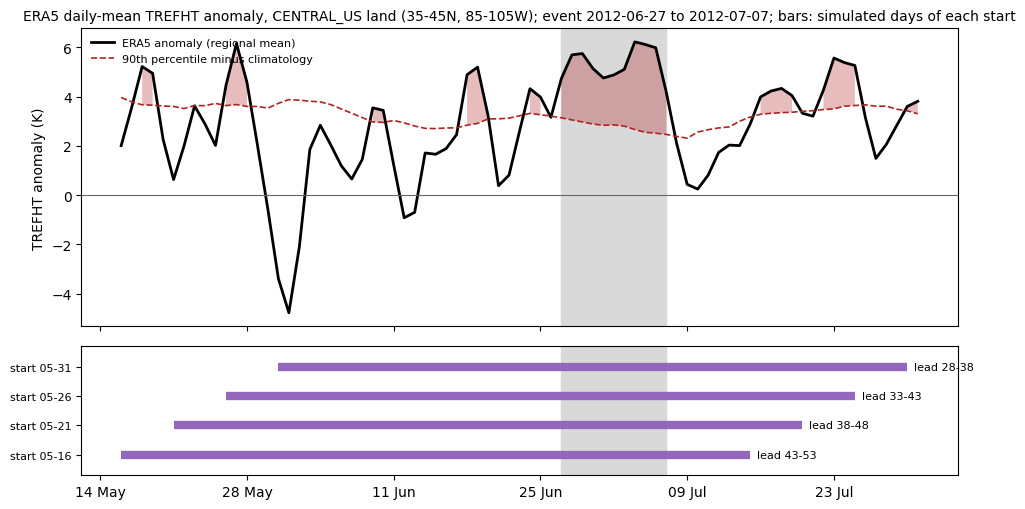

In [6]:
from util.heatwave_case import plot_coverage

label = f"{REGION['name']} land ({REGION['lat'][0]:g}-{REGION['lat'][1]:g}N, {360 - REGION['lon'][1]:g}-{360 - REGION['lon'][0]:g}W)"
save(plot_coverage(cov, window, a_obs, thr_anom,
                   title=f"ERA5 daily-mean TREFHT anomaly, {label}; event {window[0]} to {window[1]}; "
                         f"bars: simulated days of each start"), "heatwave_coverage.png")

## 6. Model fields

Daily TREFHT (mean of the four 6-hour means) and PRECT of every member on the map box (cached; reused unless `FORCE_COMPUTE`), put on calendar days.

In [7]:
from util.heatwave_case import calendar, model_box

fields = {}
for c in CONFIGS:
    for v in ("TREFHT", "PRECT"):
        fields[c, v] = model_box(c, SEASON, v, members[c], MAP_BOX, n_days=N_DAYS,
                                 cache=data_dir / f"box_{c}_{SEASON}_{v}.nc", force=FORCE_COMPUTE, **ROOTS)
        print(f"[MODEL] {c} {v}: {dict(fields[c, v].sizes)}")
if not np.allclose(fields[CONFIGS[0], "TREFHT"].lat, obs_T.lat) or not np.allclose(fields[CONFIGS[0], "TREFHT"].lon, obs_T.lon):
    raise ValueError("model and observation grids differ on the map box")


def on_calendar(da, init):
    """(member, time, lat, lon) of one start on its calendar days, within OBS_PERIOD."""
    x = da.sel(init=np.datetime64(init, "ns")).drop_vars("init", errors="ignore")
    x = x.assign_coords(lead=calendar(init, x.lead.values).astype("datetime64[ns]")).rename(lead="time")
    return x.sel(time=slice(*OBS_PERIOD))

[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


## 7. Regional series

Regional means of every member and start, all configurations: absolute temperature, anomalies against both references (`BIASES`), area fraction above the gridpoint threshold, and precipitation (daily and accumulated from the start).

In [8]:
absT, series, area, prect, precip = {}, {}, {}, {}, {}
for c in CONFIGS:
    for init in inits:
        T = on_calendar(fields[c, "TREFHT"], init)
        t = T.time.values
        absT[c, init] = region_mean(T, w)
        prect[c, init] = region_mean(on_calendar(fields[c, "PRECT"], init), w)
        precip[c, init] = prect[c, init].cumsum("time")
        for b in BIASES:
            anom_grid = T - (clim.clim_amip if b == "amip" else clim.clim_obs).sel(time=t)
            series[b, c, init] = region_mean(anom_grid, w)
            area[b, c, init] = region_mean((anom_grid > thr_anom_grid.sel(time=t)).astype("float64"), w)
print(f"[SERIES] {len(absT)} (config, start) pairs, {len(series)} anomaly series")

[SERIES] 20 (config, start) pairs, 40 anomaly series


## 8. Experiment QC

Ensemble-mean absolute error of regional-mean TREFHT on lead day 1 and week 1, every configuration. A defective initial state (`IC_DEFECT`) shows as a cold error of about 5-9 K at every start, far beyond the event-initialized DA configurations (within about 1 K); those configurations are kept out of every later score, and their errors here say nothing about the physics of their initialization. CLIM_BASE also has large day-1 errors at some starts, as expected: its atmospheric reference state is not initialized to the 2012 weather (late May 2012 was itself unusually warm). The QC series figure shows all configurations against observations (absolute error reference).

lead1_error                                   \
init                           2012-05-16 2012-05-21 2012-05-26 2012-05-31   
config     status                                                            
CLIM_BASE  scored                   -1.17      -2.66      -7.79       2.14   
HYB_BASE   IC defect: QC only       -8.77      -7.71      -8.08      -4.76   
DA_COUPLED scored                   -0.38      -0.14      -0.93      -0.24   
DA_ATM     scored                   -0.32       0.06      -0.68       0.15   
DA_LND     IC defect: QC only       -8.85      -8.06      -8.37      -5.20   

                              week1_error                                   
init                           2012-05-16 2012-05-21 2012-05-26 2012-05-31  
config     status                                                           
CLIM_BASE  scored                   -4.94      -4.51      -3.11      -0.72  
HYB_BASE   IC defect: QC only       -8.82      -9.24      -8.42      -7.01  
DA_COUPLED scored                   -0.27       0.19      -0.09       1.04  
DA_ATM     scored                   -0.26       0.18       0.05       1.40  
DA_LND     IC defect: QC only       -8.67      -9.23      -8.80      -7.18

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_qc_all_none.png


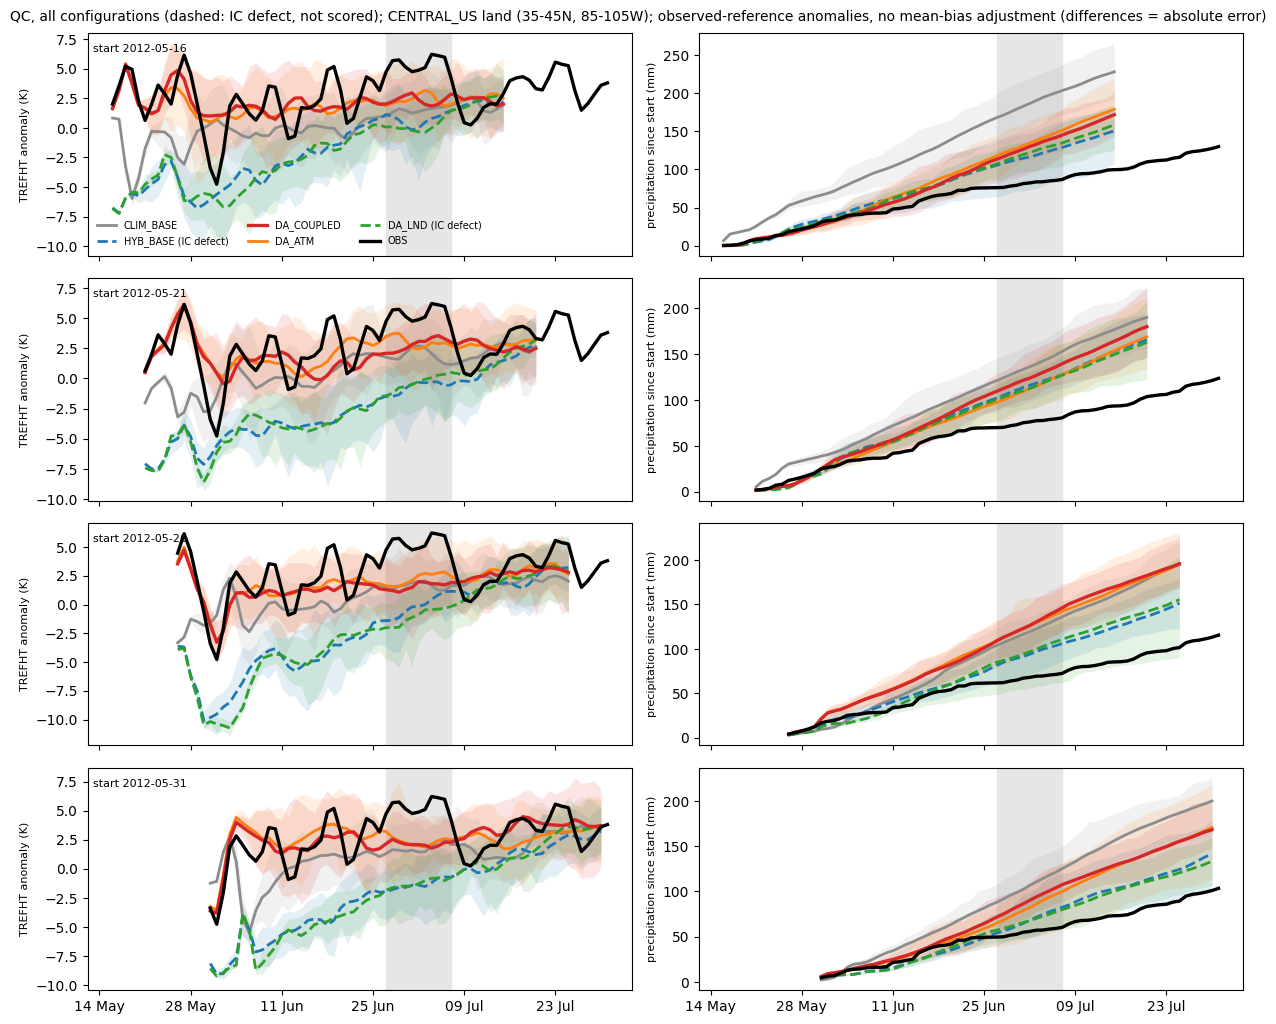

In [9]:
from util.heatwave_case import plot_series

qc_rows = []
for c in CONFIGS:
    for init in inits:
        e = absT[c, init].mean("member") - s_obs.sel(time=absT[c, init].time)
        qc_rows.append(dict(config=c, init=str(init), lead1_error=float(e.isel(time=0)),
                            week1_error=float(e.isel(time=slice(0, 7)).mean()),
                            status="IC defect: QC only" if c in IC_DEFECT else "scored"))
qc = pd.DataFrame(qc_rows)
qc.to_csv(data_dir / "init_qc.csv", index=False)
display(qc.pivot(index=["config", "status"], columns="init", values=["lead1_error", "week1_error"])
        .reindex(CONFIGS, level="config").round(2))

ylabels = {"TREFHT": "TREFHT anomaly (K)", "PRECT": "precipitation since start (mm)"}
obs_cum = {init: region_mean(obs_P, w).sel(time=slice(np.datetime64(init, "ns"), None)).cumsum("time") for init in inits}
if IC_DEFECT:
    panels = {"TREFHT": {i: {c: series["none", c, i] for c in CONFIGS} for i in inits},
              "PRECT": {i: {c: precip[c, i] for c in CONFIGS} for i in inits}}
    save(plot_series(panels, {"TREFHT": a_obs, "PRECT": obs_cum}, window, STYLE_MAP, IC_DEFECT, ylabels=ylabels,
                     spread=SPREAD, title=f"QC, all configurations (dashed: IC defect, not scored); {label}; "
                                          f"{REFERENCE_LABELS['none']}"),
         "heatwave_series_qc_all_none.png")

## 9. Start-resolved regional trajectories

Ensemble mean and member range of each scored configuration, one row per start: the Q1/Q2 experiments, then every scored one.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_primary_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_scored_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_primary_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_scored_amip.png


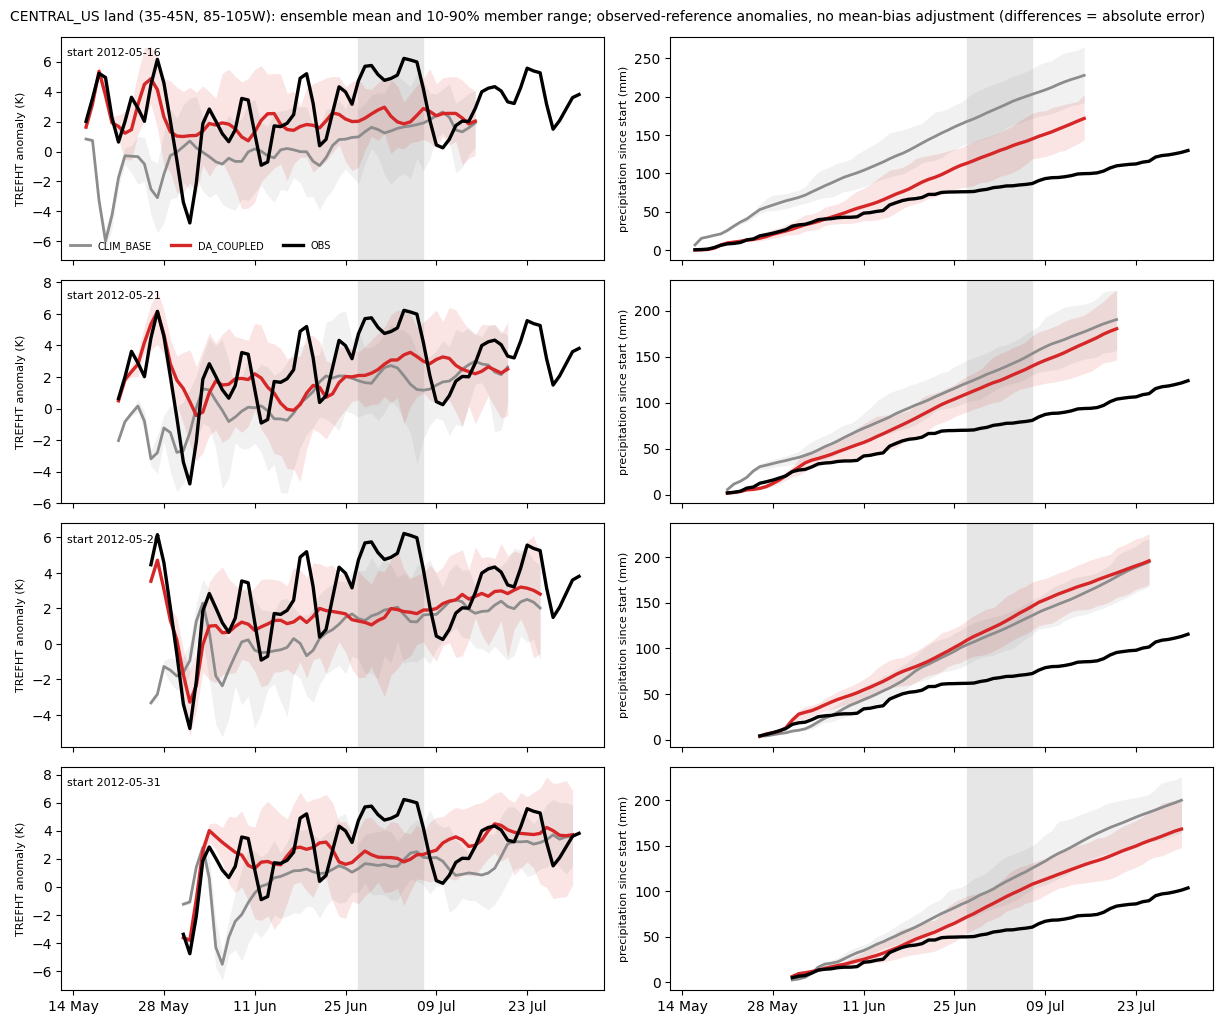

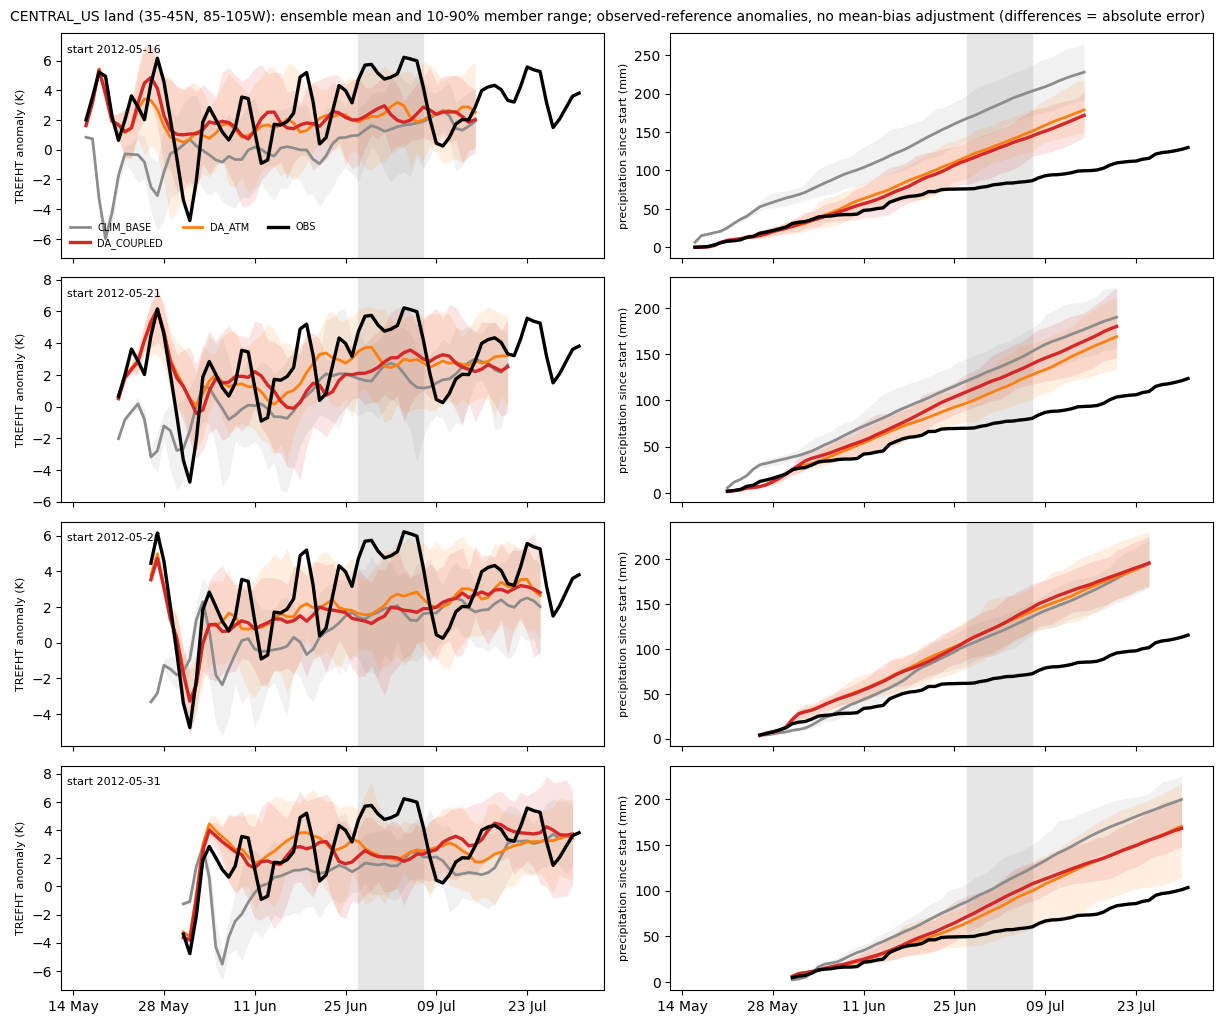

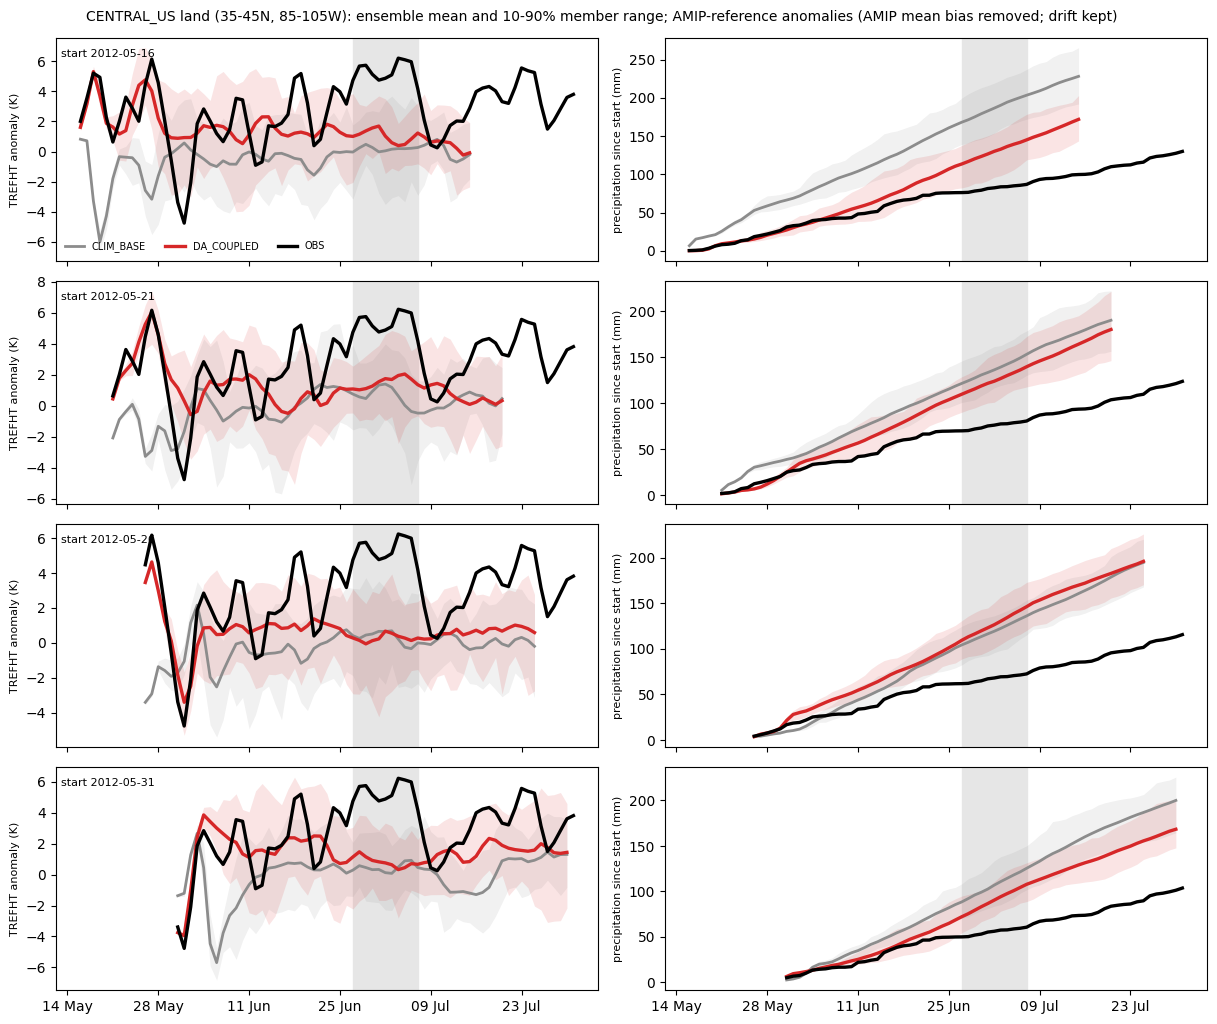

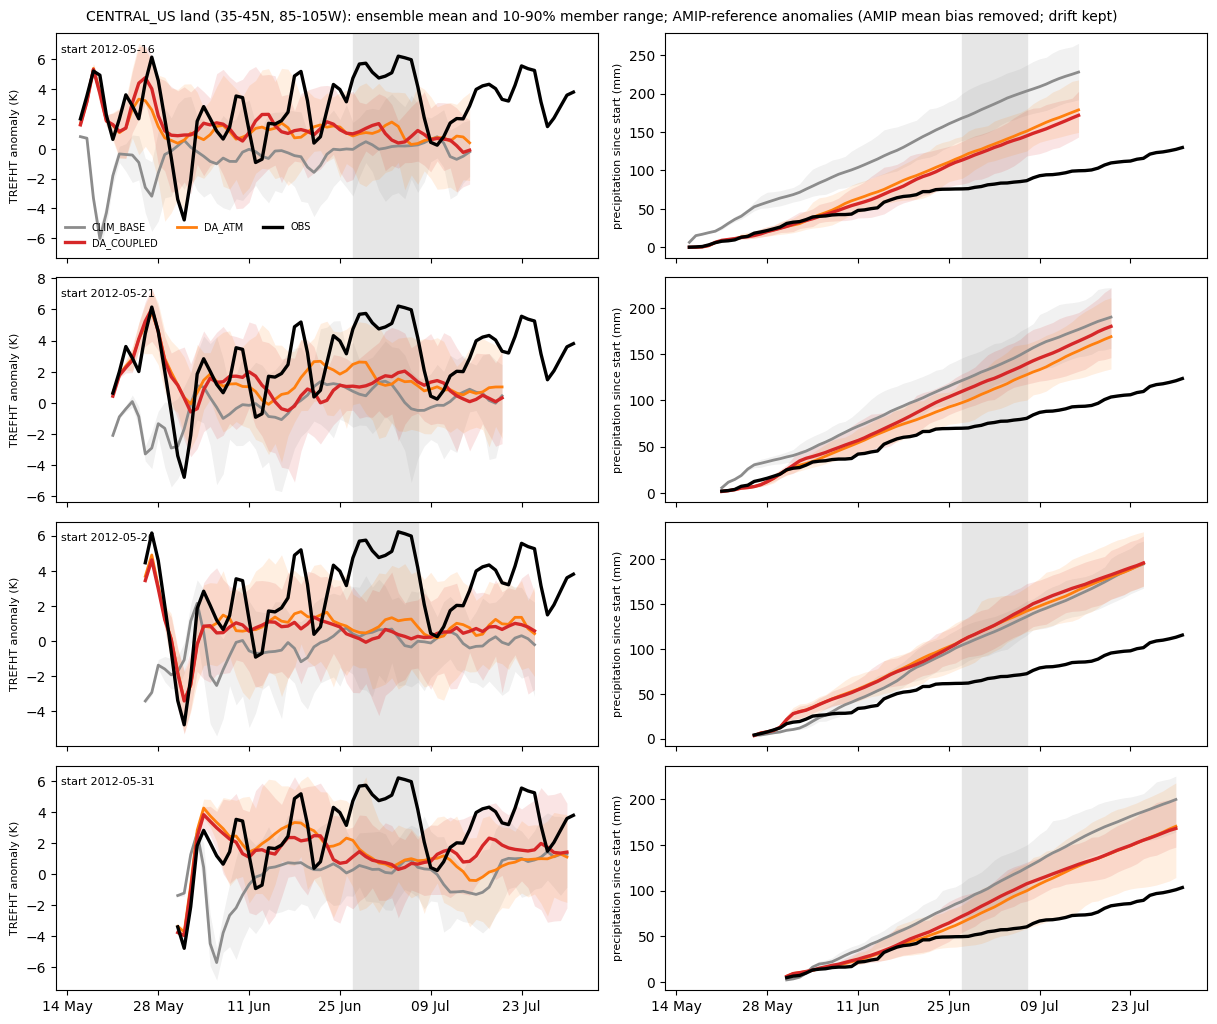

In [10]:
primary = [c for c in PRIMARY if c in SCORED]
for b in BIASES:
    for tag, cfgs in (("primary", primary), ("scored", SCORED)):
        if tag == "scored" and cfgs == primary:
            continue
        panels = {"TREFHT": {i: {c: series[b, c, i] for c in cfgs} for i in inits},
                  "PRECT": {i: {c: precip[c, i] for c in cfgs} for i in inits}}
        save(plot_series(panels, {"TREFHT": a_obs, "PRECT": obs_cum}, window, STYLE_MAP, ylabels=ylabels, spread=SPREAD,
                         title=f"{label}: ensemble mean and {int(SPREAD[0] * 100)}-{int(SPREAD[1] * 100)}% member range; "
                               f"{REFERENCE_LABELS[b]}"),
             f"heatwave_series_{tag}_{b}.png")

## 10. Fixed-event-window verification

Metrics of every member on the observed window (all configurations are computed and saved; only `SCORED` are summarized). The start-resolved summary is the primary result; the pooled summary over starts is descriptive context (the starts are not independent cases).

In [11]:
rows = []
for c in CONFIGS:
    for init in inits:
        t = absT[c, init].time.values
        th = thr_anom.sel(time=t).values
        T_event = absT[c, init].sel(time=slice(*window)).mean("time")
        p_event = prect[c, init].sel(time=slice(*window)).sum("time")
        for b in BIASES:
            for k, m in enumerate(absT[c, init].member.values):
                r = heat_metrics(series[b, c, init].isel(member=k).values, t, th, area[b, c, init].isel(member=k).values,
                                 window, obs_peak, PEAK_TOLERANCE_DAYS)
                rows.append(dict(bias=b, config=c, init=str(init), member=str(m), **r,
                                 event_mean_T=float(T_event.isel(member=k)),
                                 event_precip_mm=float(p_event.isel(member=k))))
metrics = pd.DataFrame(rows)
metrics["event_mean_T_error"] = metrics.event_mean_T - obs_metrics["event_mean_T"]
metrics.to_csv(data_dir / "heat_metrics.csv", index=False)
print(f"[WRITE] {data_dir / 'heat_metrics.csv'}")

PRIMARY_METRICS = ["event_mean_T_error", "event_mean_anomaly", "peak_anomaly", "peak_date_error_days", "exceedance_days",
                   "longest_run_days", "accumulated_exceedance", "area_fraction_mean", "event_precip_mm"]
TOLERANT_METRICS = ["peak_anomaly_tol", "peak_date_error_tol_days", "longest_run_tol_days"]
scored = metrics[metrics.config.isin(SCORED)]
by_start = (scored.groupby(["bias", "config", "init"])[PRIMARY_METRICS + TOLERANT_METRICS].median()
            .reindex(SCORED, level="config"))
print("Member medians by start (primary):")
display(by_start.round(2))
print("Pooled over starts (descriptive):")
display(scored.groupby(["bias", "config"])[PRIMARY_METRICS + TOLERANT_METRICS].median()
        .reindex(SCORED, level="config").round(2))
display(pd.DataFrame([obs_metrics], index=["OBS"])[PRIMARY_METRICS + TOLERANT_METRICS].round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics.csv
Member medians by start (primary):


event_mean_T_error  event_mean_anomaly  \
bias config     init                                                 
amip CLIM_BASE  2012-05-16               -4.45               -0.46   
                2012-05-21               -3.19                0.81   
                2012-05-26               -3.68                0.31   
                2012-05-31               -3.43                0.57   
     DA_COUPLED 2012-05-16               -3.24                0.76   
                2012-05-21               -1.91                2.08   
                2012-05-26               -3.79                0.21   
                2012-05-31               -2.96                1.04   
     DA_ATM     2012-05-16               -2.81                1.19   
                2012-05-21               -1.87                2.13   
                2012-05-26               -3.29                0.71   
                2012-05-31               -3.45                0.54   
none CLIM_BASE  2012-05-16               -4.45                0.87   
                2012-05-21               -3.19                2.13   
                2012-05-26               -3.68                1.64   
                2012-05-31               -3.43                1.90   
     DA_COUPLED 2012-05-16               -3.24                2.09   
                2012-05-21               -1.91                3.41   
                2012-05-26               -3.79                1.53   
                2012-05-31               -2.96                2.37   
     DA_ATM     2012-05-16               -2.81                2.52   
                2012-05-21               -1.87                3.46   
                2012-05-26               -3.29                2.04   
                2012-05-31               -3.45                1.87   

                            peak_anomaly  peak_date_error_days  \
bias config     init                                             
amip CLIM_BASE  2012-05-16          1.74                  -0.5   
                2012-05-21          2.94                  -3.0   
                2012-05-26          2.62                  -2.5   
                2012-05-31          2.71                   1.0   
     DA_COUPLED 2012-05-16          3.07                  -3.0   
                2012-05-21          4.13                   0.0   
                2012-05-26          2.32                  -2.0   
                2012-05-31          3.02                  -4.5   
     DA_ATM     2012-05-16          3.84                  -1.5   
                2012-05-21          4.43                  -4.0   
                2012-05-26          3.19                  -1.0   
                2012-05-31          3.38                  -2.5   
none CLIM_BASE  2012-05-16          3.27                   0.0   
                2012-05-21          4.27                  -2.5   
                2012-05-26          3.89                  -2.5   
                2012-05-31          4.08                   1.0   
     DA_COUPLED 2012-05-16          4.40                  -2.5   
                2012-05-21          5.58                   0.0   
                2012-05-26          3.68                  -1.5   
                2012-05-31          4.07                  -4.5   
     DA_ATM     2012-05-16          5.22                   0.0   
                2012-05-21          5.86                  -3.5   
                2012-05-26          4.77                  -1.0   
                2012-05-31          4.61                  -2.5   

                            exceedance_days  longest_run_days  \
bias config     init                                            
amip CLIM_BASE  2012-05-16              0.0               0.0   
                2012-05-21              1.0               1.0   
                2012-05-26              0.5               0.5   
                2012-05-31              0.5               0.5   
     DA_COUPLED 2012-05-16              1.0               1.0   
                2012-05-21         

Pooled over starts (descriptive):


event_mean_T_error  event_mean_anomaly  peak_anomaly  \
bias config                                                             
amip CLIM_BASE                -3.54                0.46          2.55   
     DA_COUPLED               -3.08                0.92          3.02   
     DA_ATM                   -3.06                0.94          3.67   
none CLIM_BASE                -3.54                1.78          3.92   
     DA_COUPLED               -3.08                2.24          4.11   
     DA_ATM                   -3.06                2.27          4.86   

                 peak_date_error_days  exceedance_days  longest_run_days  \
bias config                                                                
amip CLIM_BASE                   -2.0              0.0               0.0   
     DA_COUPLED                  -2.5              0.5               0.5   
     DA_ATM                      -2.0              2.0               2.0   
none CLIM_BASE                   -1.0              3.0               2.5   
     DA_COUPLED                  -1.5              4.0               3.0   
     DA_ATM                      -1.5              5.0               4.0   

                 accumulated_exceedance  area_fraction_mean  event_precip_mm  \
bias config                                                                    
amip CLIM_BASE                     0.00                0.09            35.82   
     DA_COUPLED                    0.02                0.12            35.97   
     DA_ATM                        1.44                0.16            33.52   
none CLIM_BASE                     2.40                0.22            35.82   
     DA_COUPLED                    2.95                0.26            35.97   
     DA_ATM                        4.89                0.31            33.52   

                 peak_anomaly_tol  peak_date_error_tol_days  \
bias config                                                   
amip CLIM_BASE               3.19                      -2.0   
     DA_COUPLED              4.18                      -3.5   
     DA_ATM                  4.65                      -6.0   
none CLIM_BASE               4.74                       1.0   
     DA_COUPLED              5.44                       0.0   
     DA_ATM                  5.99                      -2.5   

                 longest_run_tol_days  
bias config                            
amip CLIM_BASE                    1.0  
     DA_COUPLED                   3.0  
     DA_ATM                       4.0  
none CLIM_BASE                    5.0  
     DA_COUPLED                   6.0  
     DA_ATM                       7.0

,event_mean_T_error,event_mean_anomaly,peak_anomaly,peak_date_error_days,exceedance_days,longest_run_days,accumulated_exceedance,area_fraction_mean,event_precip_mm,peak_anomaly_tol,peak_date_error_tol_days,longest_run_tol_days
OBS,0.0,5.32,6.22,0,11,11,27.82,0.78,10.8,6.22,0,11


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_by_start_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_by_start_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_amip.png


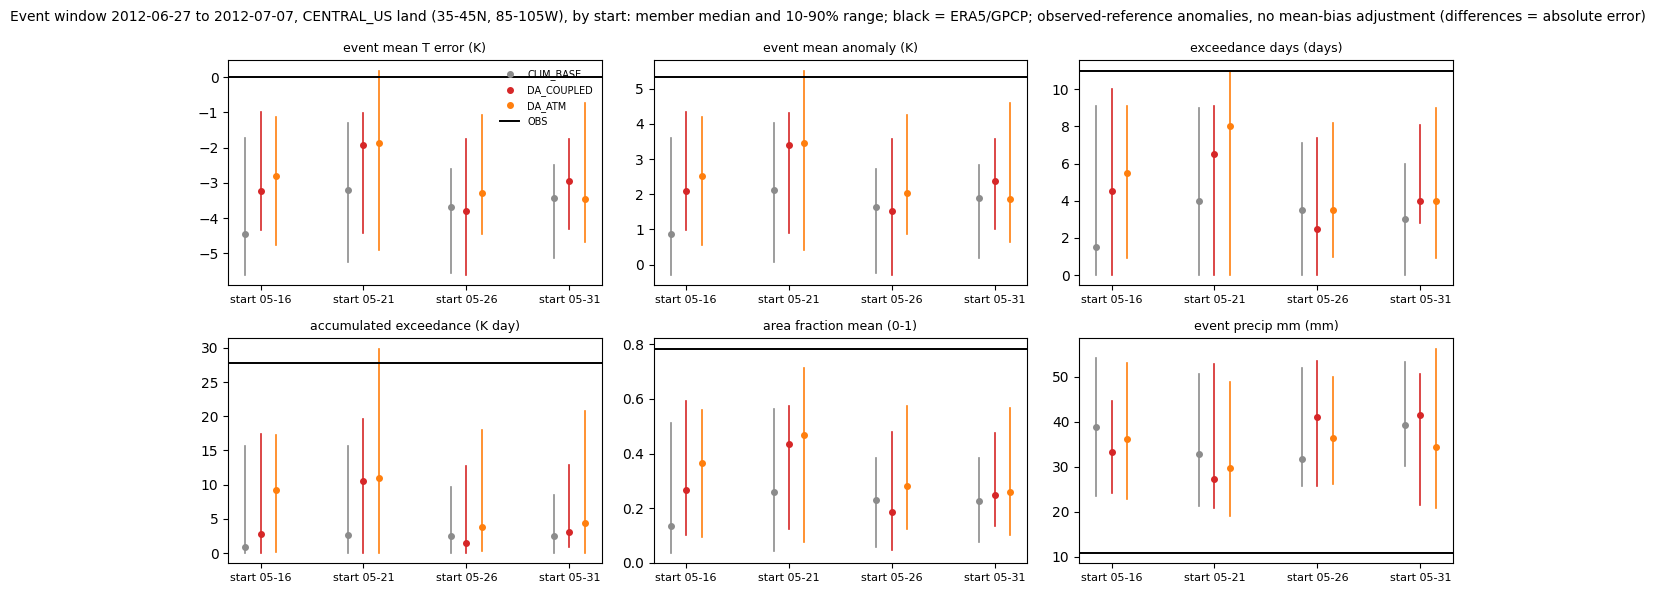

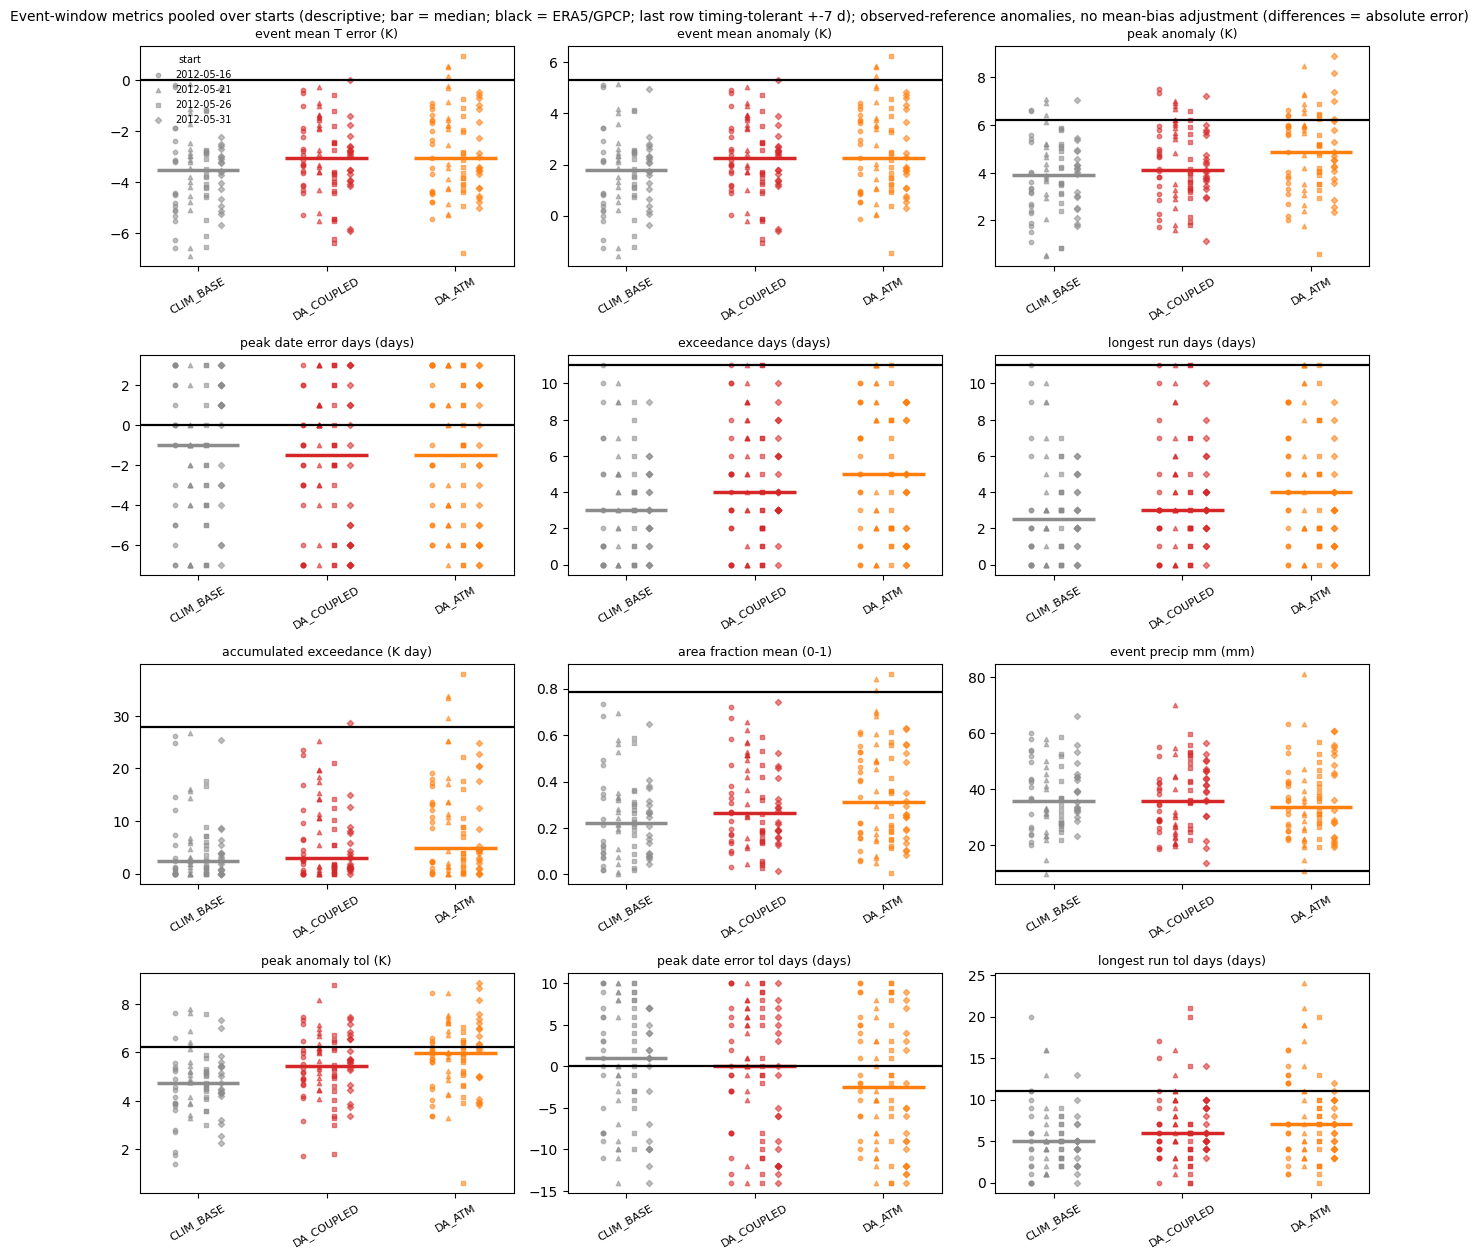

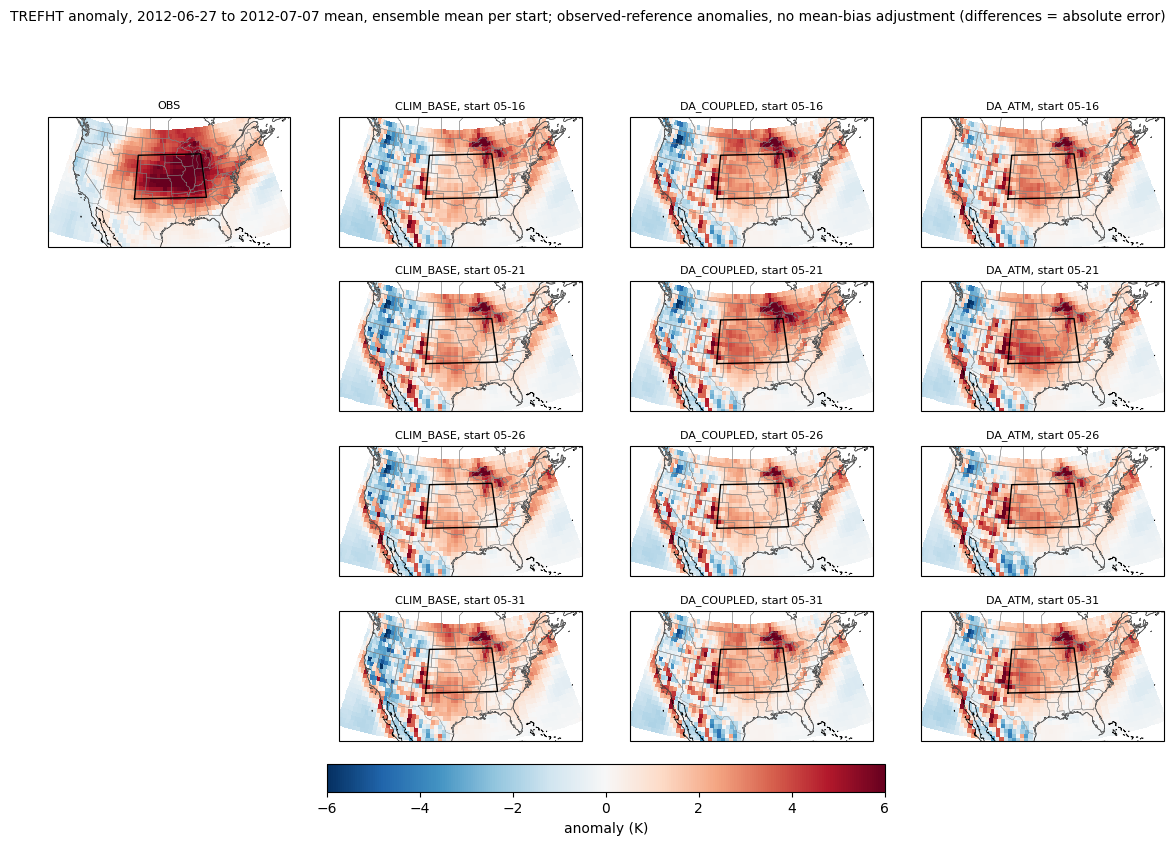

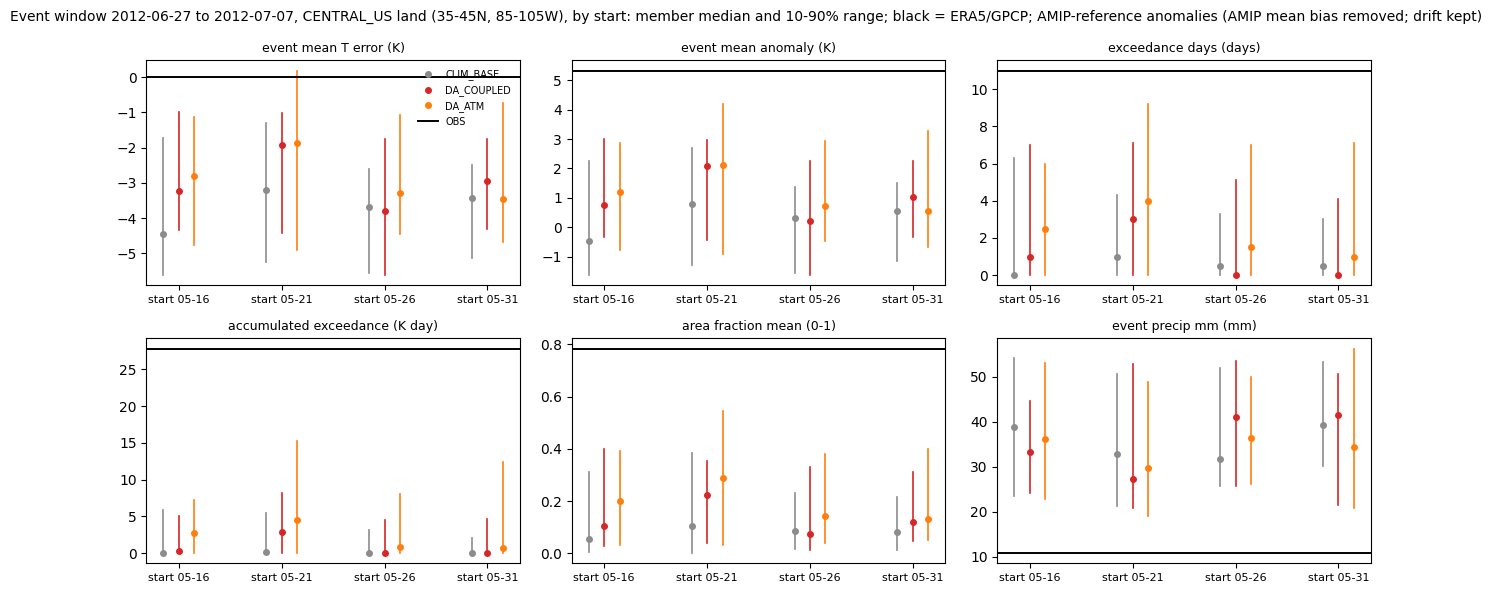

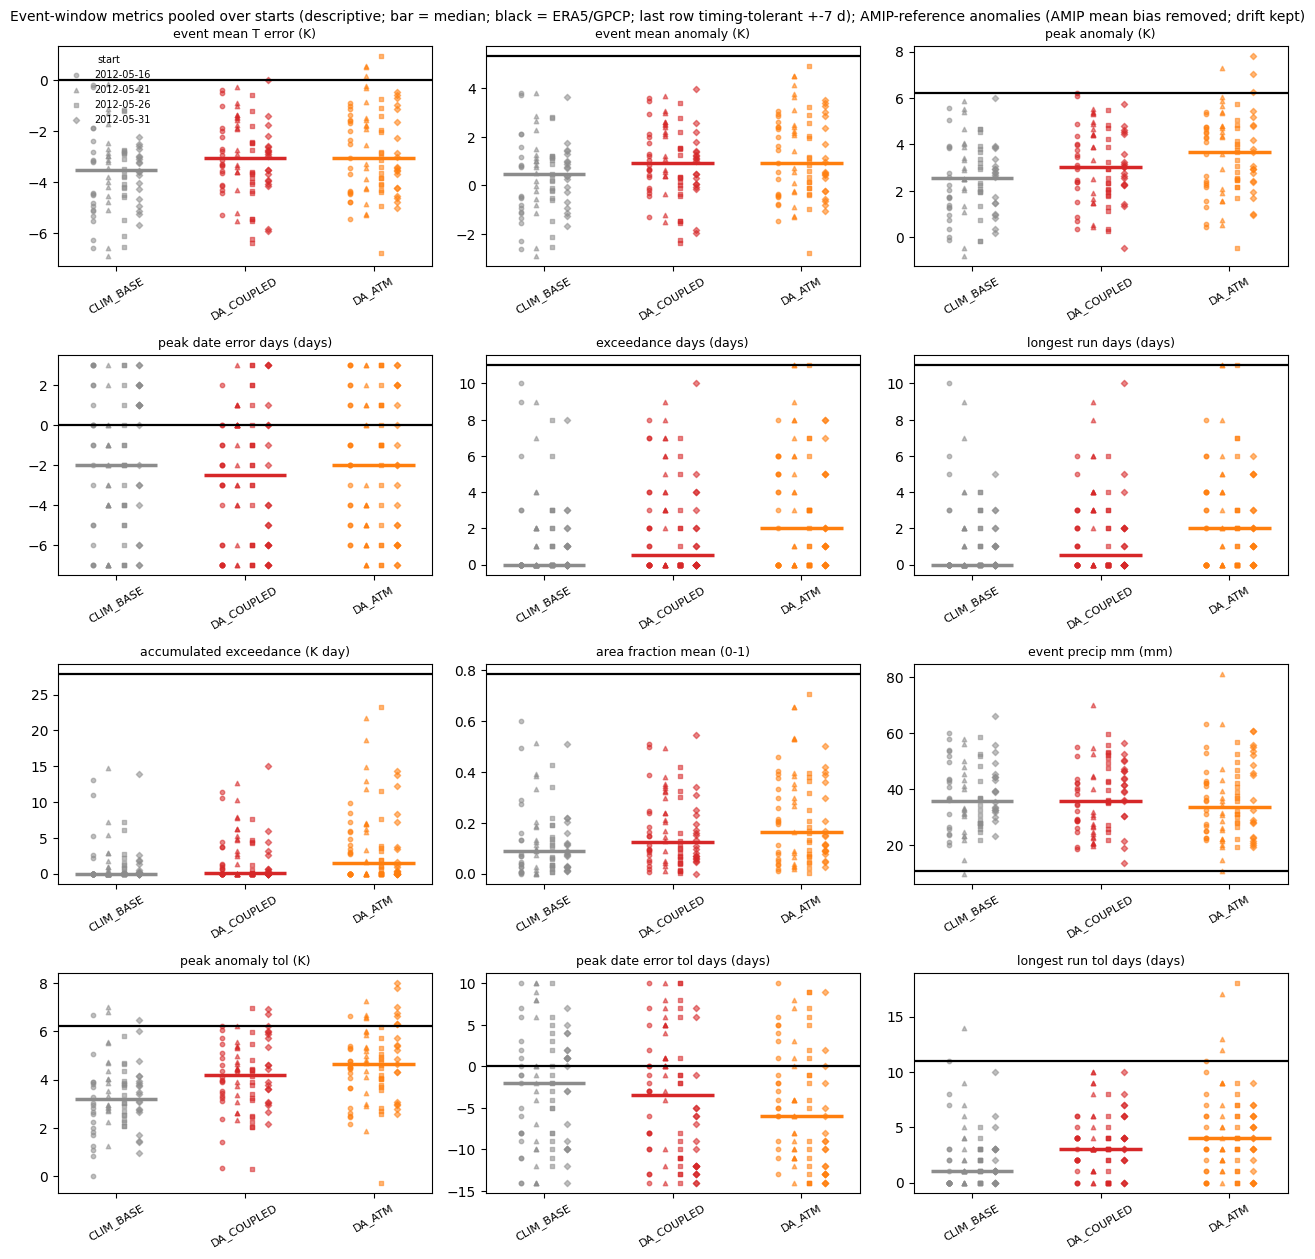

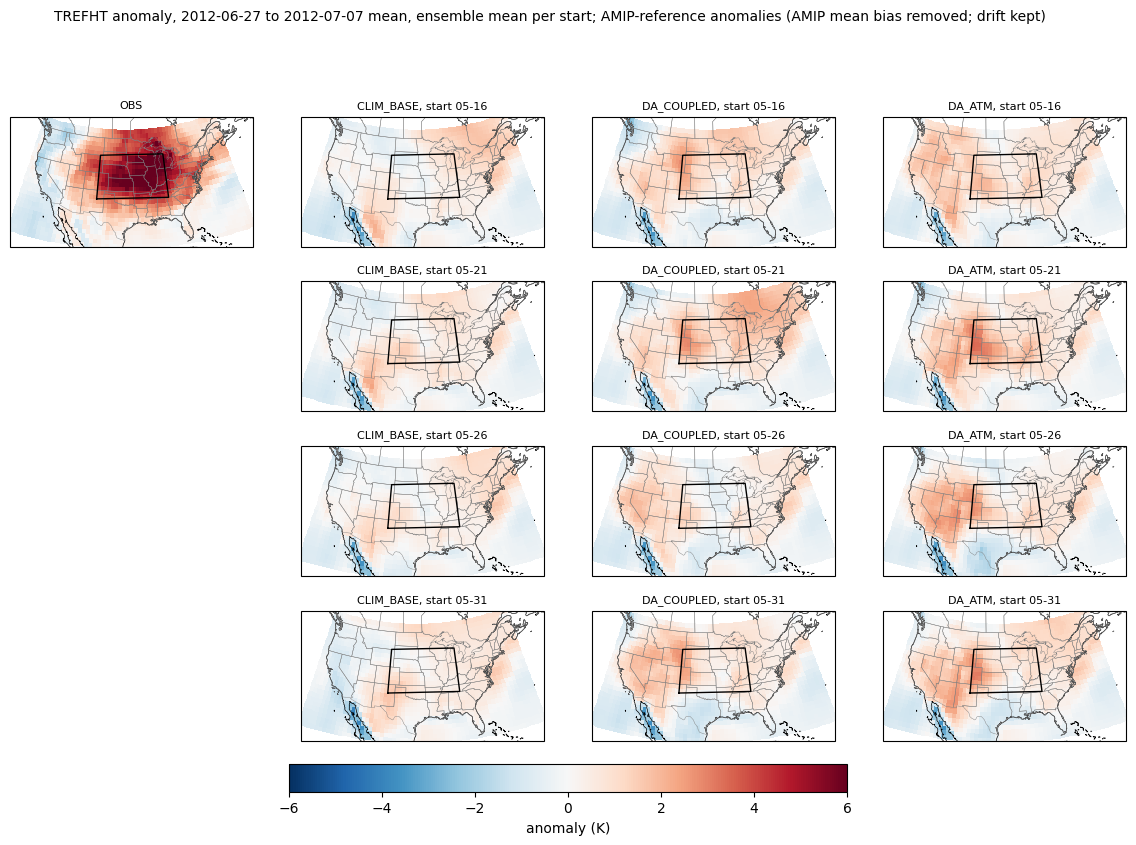

In [12]:
from util.heatwave_case import plot_by_start, plot_maps_by_start, plot_metrics

START_METRICS = ["event_mean_T_error", "event_mean_anomaly", "exceedance_days", "accumulated_exceedance",
                 "area_fraction_mean", "event_precip_mm"]
for b in BIASES:
    mb = scored[scored.bias == b]
    save(plot_by_start(mb, obs_metrics, START_METRICS, SCORED, STYLE_MAP, units=METRIC_UNITS, spread=SPREAD,
                       title=f"Event window {window[0]} to {window[1]}, {label}, by start: member median and "
                             f"{int(SPREAD[0] * 100)}-{int(SPREAD[1] * 100)}% range; black = ERA5/GPCP; {REFERENCE_LABELS[b]}"),
         f"heatwave_metrics_by_start_{b}.png")
    save(plot_metrics(mb, obs_metrics, PRIMARY_METRICS + TOLERANT_METRICS, SCORED, STYLE_MAP, units=METRIC_UNITS,
                      title=f"Event-window metrics pooled over starts (descriptive; bar = median; black = ERA5/GPCP; "
                            f"last row timing-tolerant +-{PEAK_TOLERANCE_DAYS} d); {REFERENCE_LABELS[b]}"),
         f"heatwave_metrics_{b}.png")
    ref = clim.clim_amip if b == "amip" else clim.clim_obs
    obs_map = (obs_T - clim.clim_obs).sel(time=slice(*window)).mean("time")
    maps = {i: {c: (on_calendar(fields[c, "TREFHT"], i) - ref).sel(time=slice(*window)).mean(("time", "member"))
                for c in SCORED} for i in inits}
    save(plot_maps_by_start(obs_map, maps, REGION,
                            title=f"TREFHT anomaly, {window[0]} to {window[1]} mean, ensemble mean per start; "
                                  f"{REFERENCE_LABELS[b]}"),
         f"heatwave_maps_{b}.png")

## 11. S2S lead-window verification

Regional-mean TREFHT averaged over the lead windows `LEAD_WINDOWS` (lead 1 = the start date) of each start, against ERA5 on the same days: ensemble-mean error, member spread and CRPS. With `none` these are scores of the absolute temperature (primary); with `amip` of the AMIP-reference anomaly against the observed anomaly (supplementary). Shaded windows overlap the observed event for that start.

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/lead_window_scores.csv
CRPS (K), observed-reference anomalies, no mean-bias adjustment (differences = absolute error):


config                CLIM_BASE  DA_COUPLED  DA_ATM
init       window                                  
2012-05-16 week 1          4.75        0.16    0.14
           week 2          4.29        0.39    0.72
           weeks 3-4       0.36        0.52    0.53
           weeks 5-6       1.79        0.44    0.61
           weeks 7-8       1.85        1.44    1.21
2012-05-21 week 1          4.38        0.14    0.15
           week 2          0.60        1.10    1.51
           weeks 3-4       0.94        0.40    0.41
           weeks 5-6       1.61        1.63    0.55
           weeks 7-8       0.66        0.27    0.50
2012-05-26 week 1          2.92        0.14    0.13
           week 2          0.83        0.62    0.56
           weeks 3-4       1.43        0.41    0.45
           weeks 5-6       2.76        2.52    2.12
           weeks 7-8       0.31        0.38    0.49
2012-05-31 week 1          0.52        0.83    1.19
           week 2          1.90        0.48    0.46
           weeks 3-4       1.34        0.61    0.48
           weeks 5-6       1.72        1.19    1.01
           weeks 7-8       1.20        0.29    0.61

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_lead_scores_none.png
CRPS (K), AMIP-reference anomalies (AMIP mean bias removed; drift kept):


config                CLIM_BASE  DA_COUPLED  DA_ATM
init       window                                  
2012-05-16 week 1          4.79        0.18    0.16
           week 2          4.38        0.43    0.76
           weeks 3-4       0.42        0.49    0.49
           weeks 5-6       2.30        0.70    0.87
           weeks 7-8       3.23        2.76    2.61
2012-05-21 week 1          4.45        0.12    0.14
           week 2          0.66        1.00    1.40
           weeks 3-4       1.09        0.48    0.53
           weeks 5-6       2.30        2.48    1.10
           weeks 7-8       2.07        1.32    1.45
2012-05-26 week 1          3.03        0.16    0.13
           week 2          0.94        0.70    0.63
           weeks 3-4       1.79        0.64    0.56
           weeks 5-6       3.93        3.69    3.22
           weeks 7-8       1.97        1.39    1.04
2012-05-31 week 1          0.65        0.70    1.05
           week 2          2.08        0.42    0.38
           weeks 3-4       1.83        0.77    0.34
           weeks 5-6       3.17        2.57    2.31
           weeks 7-8       3.26        1.49    2.44

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_lead_scores_amip.png


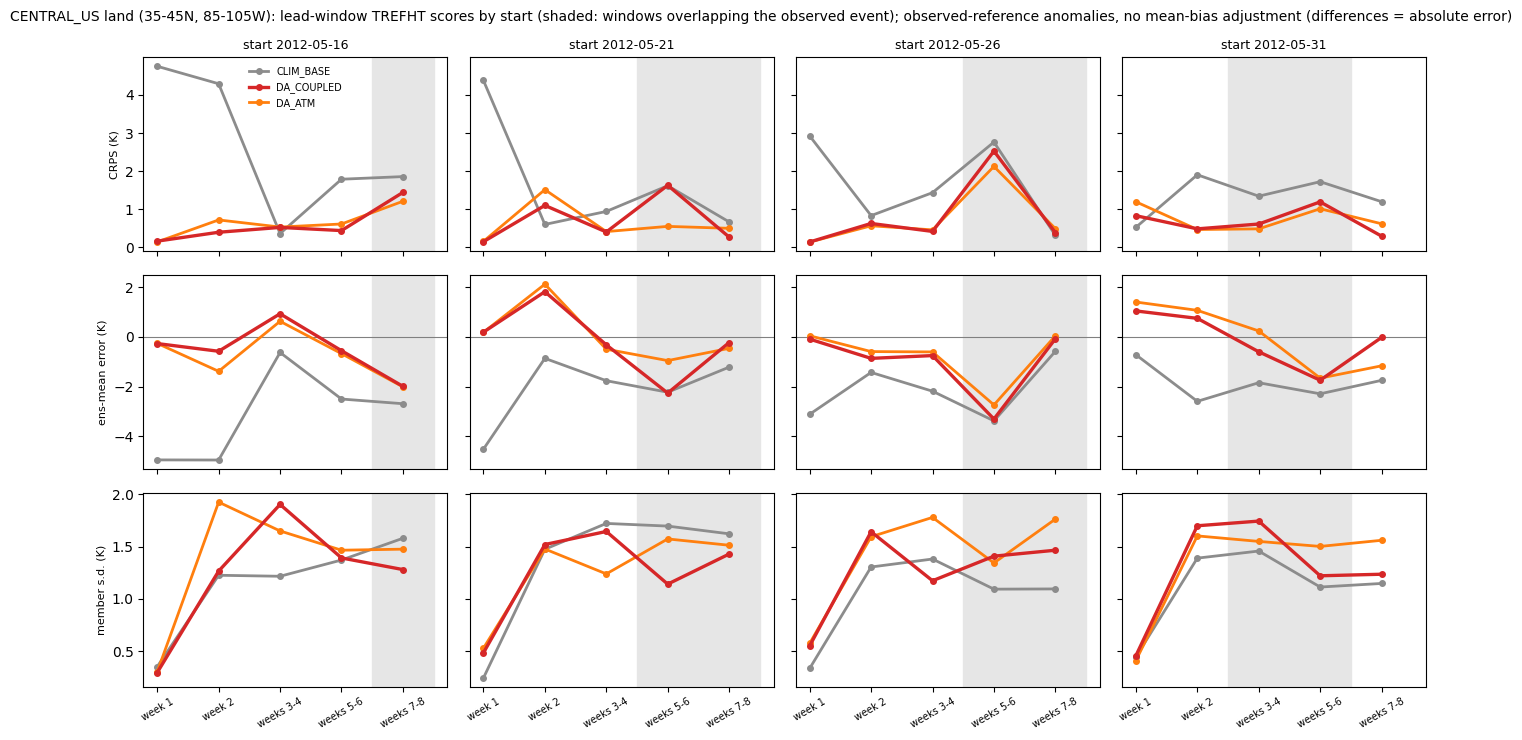

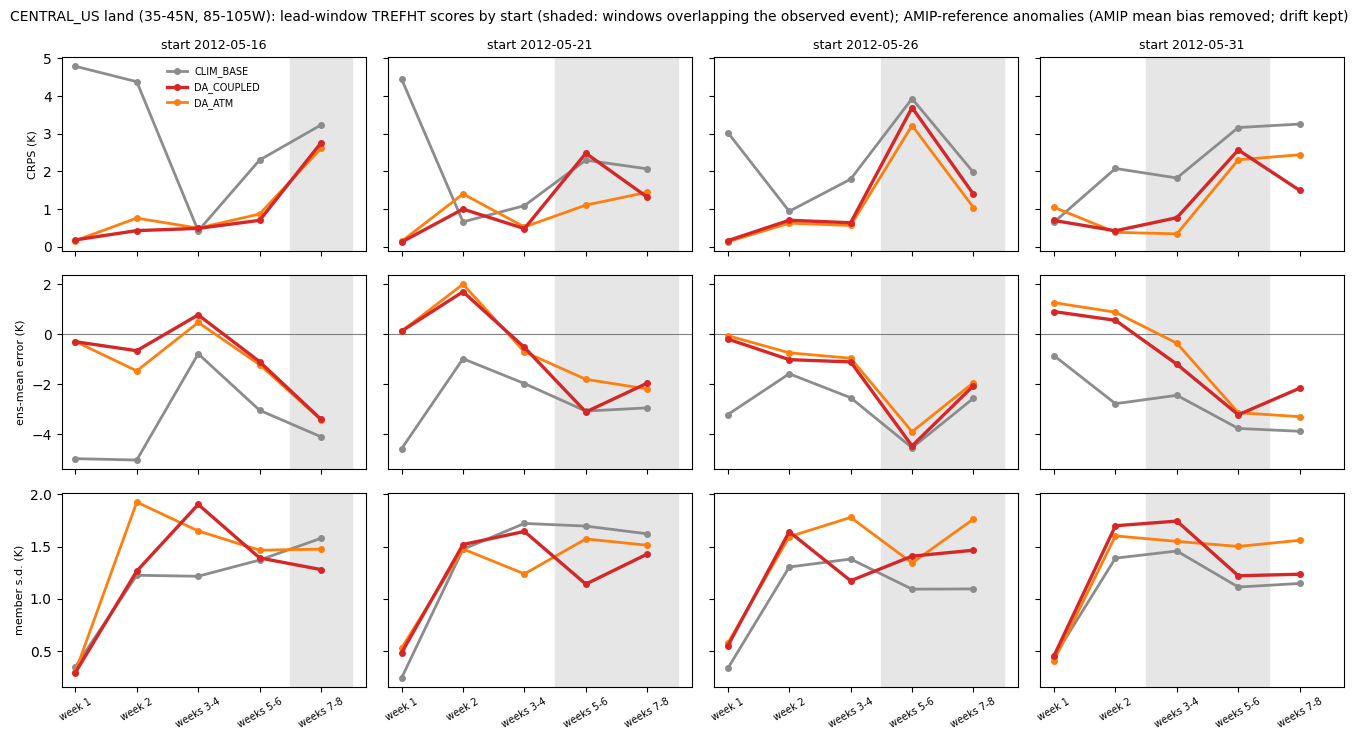

In [13]:
from util.heatwave_case import lead_window_scores, plot_lead_scores

lead_rows = []
for b in BIASES:
    for c in CONFIGS:
        for init in inits:
            for r in lead_window_scores(series[b, c, init], a_obs, init, LEAD_WINDOWS):
                lead_rows.append(dict(bias=b, config=c, init=str(init), **r))
lead_scores = pd.DataFrame(lead_rows)
lead_scores.to_csv(data_dir / "lead_window_scores.csv", index=False)
print(f"[WRITE] {data_dir / 'lead_window_scores.csv'}")
ls = lead_scores[lead_scores.config.isin(SCORED)]
for b in BIASES:
    print(f"CRPS (K), {REFERENCE_LABELS[b]}:")
    display(ls[ls.bias == b].pivot(index=["init", "window"], columns="config", values="crps")[SCORED].round(2))
    save(plot_lead_scores(ls[ls.bias == b], SCORED, STYLE_MAP,
                          {"crps": "CRPS (K)", "ens_mean_error": "ens-mean error (K)", "spread": "member s.d. (K)"},
                          event_leads=event_leads,
                          title=f"{label}: lead-window TREFHT scores by start (shaded: windows overlapping the "
                                f"observed event); {REFERENCE_LABELS[b]}"),
         f"heatwave_lead_scores_{b}.png")

## 12. Event-window ensemble scores and event probability

Per start: CRPS of the event-window mean anomaly (with `none`, equal to the CRPS of the absolute event-mean temperature), the event probability $p$ (member fraction with at least `MIN_EVENT_DAYS` consecutive hot days in the observed window) and its Brier score $(p - y)^2$; the same with the timing-tolerant window. One observed event: these describe this case only (see the Metrics note above).

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/event_scores.csv; observed outcome y = 1 (tolerant: 1)


,,,crps_event_mean,ens_mean_error,p_event,brier,p_event_tol,brier_tol
bias,config,init,,,,,,
none,CLIM_BASE,2012-05-16,2.819,-3.815,0.35,0.423,0.65,0.122
amip,CLIM_BASE,2012-05-16,4.147,-5.143,0.25,0.562,0.25,0.562
none,CLIM_BASE,2012-05-21,2.498,-3.414,0.55,0.202,0.75,0.062
amip,CLIM_BASE,2012-05-21,3.826,-4.742,0.20,0.640,0.40,0.360
none,CLIM_BASE,2012-05-26,2.974,-3.711,0.60,0.160,0.85,0.023
amip,CLIM_BASE,2012-05-26,4.301,-5.038,0.25,0.562,0.30,0.490
none,CLIM_BASE,2012-05-31,2.882,-3.551,0.50,0.250,0.75,0.062
amip,CLIM_BASE,2012-05-31,4.209,-4.879,0.15,0.722,0.40,0.360
none,DA_COUPLED,2012-05-16,2.252,-2.966,0.55,0.202,0.95,0.003


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_event_probability_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_event_probability_amip.png


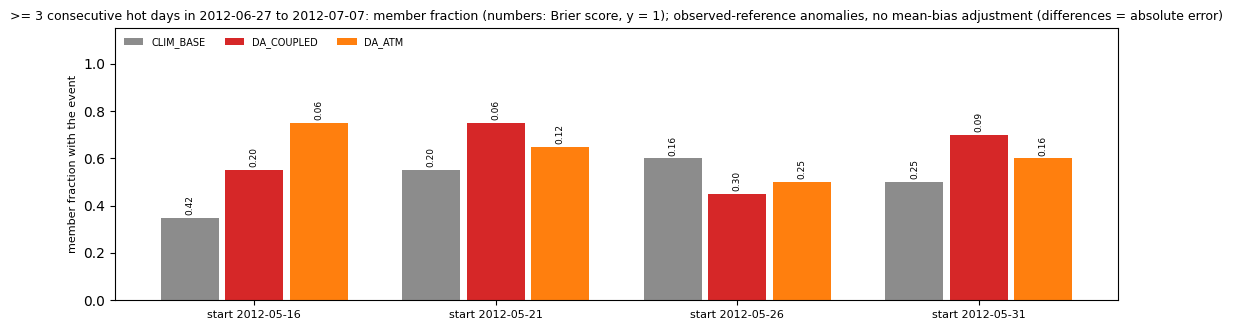

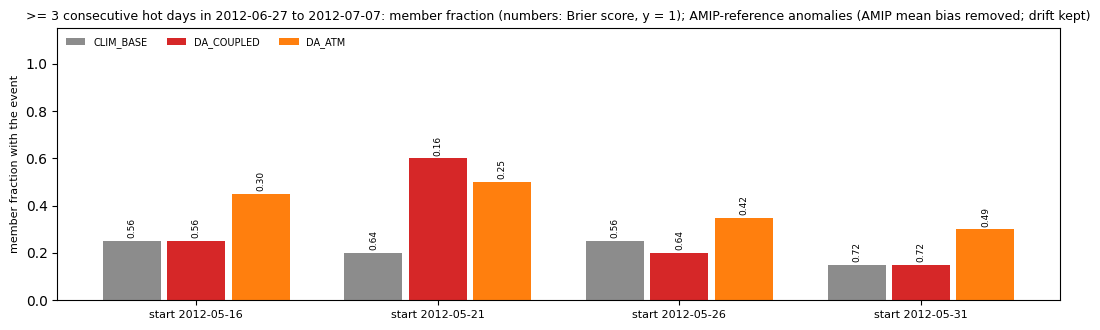

In [14]:
from util.heatwave_case import crps_ensemble, plot_event_probability

ens_rows = []
for (b, c, i), g in metrics.groupby(["bias", "config", "init"], sort=False):
    p = float((g.longest_run_days >= MIN_EVENT_DAYS).mean())
    p_tol = float((g.longest_run_tol_days >= MIN_EVENT_DAYS).mean())
    ens_rows.append(dict(bias=b, config=c, init=i, n_members=len(g),
                         crps_event_mean=crps_ensemble(g.event_mean_anomaly, obs_metrics["event_mean_anomaly"]),
                         ens_mean_error=float(g.event_mean_anomaly.mean() - obs_metrics["event_mean_anomaly"]),
                         p_event=p, brier=(p - y_obs) ** 2, p_event_tol=p_tol, brier_tol=(p_tol - y_obs_tol) ** 2))
event_scores = pd.DataFrame(ens_rows)
event_scores.to_csv(data_dir / "event_scores.csv", index=False)
print(f"[WRITE] {data_dir / 'event_scores.csv'}; observed outcome y = {y_obs} (tolerant: {y_obs_tol})")
es = event_scores[event_scores.config.isin(SCORED)]
display(es.set_index(["bias", "config", "init"]).drop(columns="n_members").reindex(SCORED, level="config").round(3))
for b in BIASES:
    save(plot_event_probability(es[es.bias == b], SCORED, STYLE_MAP,
                                title=f">= {MIN_EVENT_DAYS} consecutive hot days in {window[0]} to {window[1]}: member "
                                      f"fraction (numbers: Brier score, y = {y_obs}); {REFERENCE_LABELS[b]}"),
         f"heatwave_event_probability_{b}.png")

## 13. Initialization contrasts

Difference between two scored experiments (`CONTRASTS`, a minus b) per start, with a 90 % bootstrap interval from resampling the members of each ensemble independently (no member pairing). Event-mean anomaly and precipitation differences do not depend on the reference (the same climatology is subtracted from both); threshold counts and CRPS do. For CRPS a negative difference favours a.

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/contrasts.csv; pairs: [('DA_COUPLED', 'CLIM_BASE'), ('DA_ATM', 'CLIM_BASE'), ('DA_COUPLED', 'DA_ATM')]


metric                                  event_mean_anomaly  exceedance_days  \
bias contrast               init                                              
amip DA_ATM - CLIM_BASE     2012-05-16                0.85             1.15   
                            2012-05-21                1.11             2.45   
                            2012-05-26                0.62             1.00   
                            2012-05-31                0.60             1.30   
     DA_COUPLED - CLIM_BASE 2012-05-16                0.85             0.50   
                            2012-05-21                0.92             1.60   
                            2012-05-26               -0.02            -0.20   
                            2012-05-31                0.37             0.45   
     DA_COUPLED - DA_ATM    2012-05-16               -0.00            -0.65   
                            2012-05-21               -0.20            -0.85   
                            2012-05-26               -0.65            -1.20   
                            2012-05-31               -0.23            -0.85   
none DA_ATM - CLIM_BASE     2012-05-16                0.85             2.00   
                            2012-05-21                1.11             2.10   
                            2012-05-26                0.62             1.05   
                            2012-05-31                0.60             1.20   
     DA_COUPLED - CLIM_BASE 2012-05-16                0.85             1.15   
                            2012-05-21                0.92             1.60   
                            2012-05-26               -0.02             0.25   
                            2012-05-31                0.37             1.65   
     DA_COUPLED - DA_ATM    2012-05-16               -0.00            -0.85   
                            2012-05-21               -0.20            -0.50   
                            2012-05-26               -0.65            -0.80   
                            2012-05-31               -0.23             0.45   

metric                                  event_precip_mm  crps_event_mean  
bias contrast               init                                          
amip DA_ATM - CLIM_BASE     2012-05-16            -2.41            -0.69  
                            2012-05-21            -1.87            -1.28  
                            2012-05-26             1.53            -0.79  
                            2012-05-31            -2.05            -0.77  
     DA_COUPLED - CLIM_BASE 2012-05-16            -4.52            -0.57  
                            2012-05-21            -1.73            -0.79  
                            2012-05-26             6.14            -0.13  
                            2012-05-31            -0.71            -0.42  
     DA_COUPLED - DA_ATM    2012-05-16            -2.12             0.12  
                            2012-05-21             0.14             0.48  
                            2012-05-26             4.61             0.66  
                            2012-05-31             1.34             0.35  
none DA_ATM - CLIM_BASE     2012-05-16            -2.41            -0.69  
                            2012-05-21            -1.87            -1.16  
                            2012-05-26             1.53            -0.70  
                            2012-05-31            -2.05            -0.77  
     DA_COUPLED - CLIM_BASE 2012-05-16            -4.52            -0.57  
                            2012-05-21            -1.73            -0.79  
                            2012-05-26             6.14            -0.13  
                            2012-05-31            -0.71            -0.42  
     DA_COUPLED - DA_ATM    2012-05-16            -2.12             0.12  
                            2012-05-21             0.14             0.37  
                            2012-05-26             4.61             0.57  
                            2012-05-31             1.34             0.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_contrasts_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_contrasts_amip.png


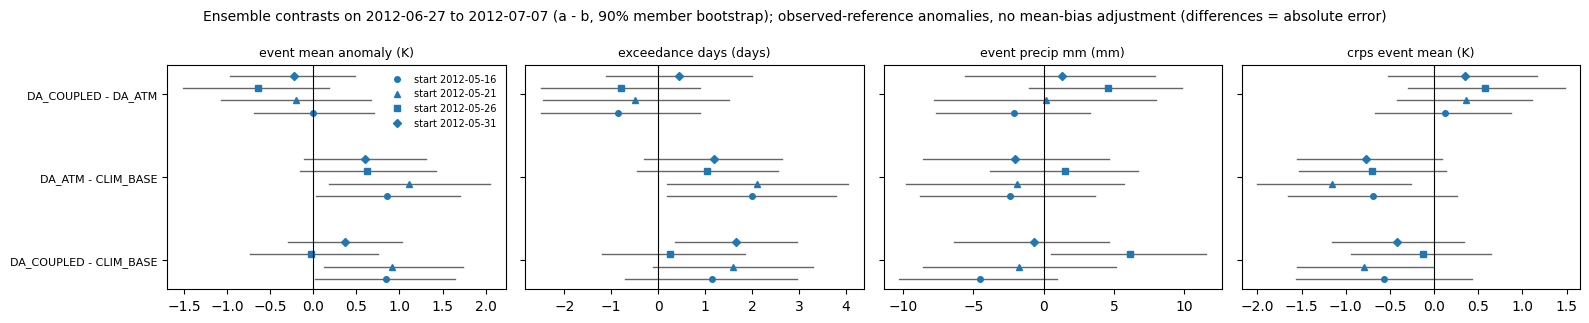

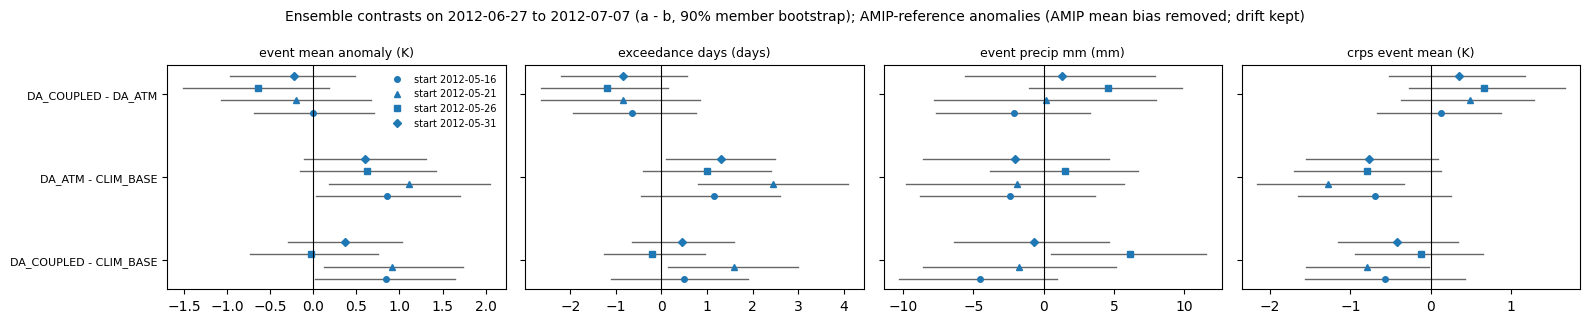

In [15]:
from util.heatwave_case import bootstrap_contrast, plot_contrasts

CONTRAST_METRICS = ["event_mean_anomaly", "exceedance_days", "event_precip_mm", "crps_event_mean"]
pairs = [(a, b) for a, b in CONTRASTS if a in SCORED and b in SCORED]
o = obs_metrics["event_mean_anomaly"]
con_rows = []
for bias in BIASES:
    mb = metrics[metrics.bias == bias]
    for a, b in pairs:
        for i in map(str, inits):
            A, B = (mb[(mb.config == x) & (mb.init == i)] for x in (a, b))
            for m in CONTRAST_METRICS:
                if m == "crps_event_mean":
                    r = bootstrap_contrast(A.event_mean_anomaly, B.event_mean_anomaly,
                                           stat=lambda x: crps_ensemble(x, o), n_boot=N_BOOT)
                else:
                    r = bootstrap_contrast(A[m], B[m], n_boot=N_BOOT)
                con_rows.append(dict(bias=bias, contrast=f"{a} - {b}", init=i, metric=m, **r))
contrasts = pd.DataFrame(con_rows)
contrasts.to_csv(data_dir / "contrasts.csv", index=False)
print(f"[WRITE] {data_dir / 'contrasts.csv'}; pairs: {pairs}")
display(contrasts.pivot(index=["bias", "contrast", "init"], columns="metric", values="diff")[CONTRAST_METRICS].round(2))
for bias in BIASES:
    save(plot_contrasts(contrasts[contrasts.bias == bias], CONTRAST_METRICS, units=METRIC_UNITS,
                        title=f"Ensemble contrasts on {window[0]} to {window[1]} (a - b, 90% member bootstrap); "
                              f"{REFERENCE_LABELS[bias]}"),
         f"heatwave_contrasts_{bias}.png")

## 14. Sensitivity of the event definition

The calendar-day threshold recomputed from other ERA5 reference periods (`SENS_THRESHOLD_YEARS`, `EXCLUDE_YEARS` left out) and percentiles (`SENS_PERCENTILES`), on the fixed event window: observed hot days and longest run, and the event probability of each scored experiment and start. Absolute temperatures are compared with the absolute threshold (no climatology involved).

In [16]:
sens_rows = []
for y0, y1 in SENS_THRESHOLD_YEARS:
    ys = [y for y in range(y0, y1 + 1) if y not in EXCLUDE_YEARS]
    for q in SENS_PERCENTILES:
        th = percentile_threshold("TREFHT", *OBS_PERIOD, ys, MAP_BOX, w, q=q, half_window=HALF_WINDOW,
                                  observation_root=OBSERVATION_ROOT).thr_region
        hot = (s_obs > th).sel(time=slice(*window)).values
        base = dict(threshold_years=f"{y0}-{y1}", percentile=q, obs_hot_days=int(hot.sum()),
                    obs_longest_run=max((e - s + 1 for s, e in runs(hot)), default=0))
        for c in SCORED:
            for init in inits:
                x = absT[c, init]
                hot_m = (x > th.sel(time=x.time)).sel(time=slice(*window)).values      # (member, time)
                longest = [max((e - s + 1 for s, e in runs(h)), default=0) for h in hot_m]
                sens_rows.append(dict(base, config=c, init=str(init),
                                      p_event=float(np.mean(np.array(longest) >= MIN_EVENT_DAYS))))
sens = pd.DataFrame(sens_rows)
sens.to_csv(data_dir / "threshold_sensitivity.csv", index=False)
print(f"[WRITE] {data_dir / 'threshold_sensitivity.csv'}")
display(sens.drop_duplicates(["threshold_years", "percentile"])[["threshold_years", "percentile", "obs_hot_days",
                                                                 "obs_longest_run"]])
display(sens.pivot(index=["threshold_years", "percentile"], columns=["config", "init"], values="p_event")
        .reindex(columns=SCORED, level="config").round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/threshold_sensitivity.csv


,threshold_years,percentile,obs_hot_days,obs_longest_run
0,2001-2014,0.85,11,11
12,2001-2014,0.90,11,11
24,2001-2014,0.95,11,11
36,1991-2020,0.85,11,11
48,1991-2020,0.90,11,11
60,1991-2020,0.95,11,11


config                      CLIM_BASE                                   \
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31   
threshold_years percentile                                               
1991-2020       0.85             0.40       0.75        0.7       0.60   
                0.90             0.35       0.50        0.6       0.45   
                0.95             0.30       0.35        0.5       0.35   
2001-2014       0.85             0.50       0.80        0.7       0.65   
                0.90             0.35       0.55        0.6       0.50   
                0.95             0.30       0.30        0.5       0.35   

config                     DA_COUPLED                                   \
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31   
threshold_years percentile                                               
1991-2020       0.85             0.60       0.80       0.65       0.75   
                0.90             0.45       0.65       0.40       0.60   
                0.95             0.35       0.60       0.35       0.35   
2001-2014       0.85             0.65       0.80       0.65       0.75   
                0.90             0.55       0.75       0.45       0.70   
                0.95             0.35       0.60       0.35       0.35   

config                         DA_ATM                                   
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31  
threshold_years percentile                                              
1991-2020       0.85             0.80       0.65       0.70       0.70  
                0.90             0.70       0.65       0.50       0.60  
                0.95             0.55       0.55       0.45       0.50  
2001-2014       0.85             0.80       0.65       0.65       0.75  
                0.90             0.75       0.65       0.50       0.60  
                0.95             0.55       0.55       0.45       0.55

## 15. Limitations and next steps

* **One event, overlapping starts.** Four starts five days apart of one event: the scores are case-specific sensitivities, not climatological forecast skill, and the Brier score of one observed event says nothing about reliability, discrimination or false alarms.
* **Reference state.** No lead-dependent hindcast climatology exists for these starts; the AMIP adjustment removes only the background model mean difference. The threshold and climatologies use 2001-2014 without 2012; section 14 shows how much the event definition depends on that choice.
* **Prescribed observed SST.** Every experiment shares the observed SST, so differences come from the atmosphere and land initial states and their evolution only.
* **Excluded experiments.** HYB_BASE and DA_LND (`IC_DEFECT`) answer nothing until rerun; Q2 and the DA_LND part of Q3 remain open.
* **Mechanism (next notebook).** Where the scored experiments underestimate sustained heat while producing more event precipitation than GPCP, that is a working hypothesis to test, not a cause: antecedent precipitation and soil moisture, latent and sensible heat fluxes, net radiation and cloud, and the location and persistence of the ridge (Z500). Similar pooled DA_COUPLED and DA_ATM results call for the start-resolved contrasts above before concluding that land initialization has little effect.